# Exercícios 3.1 – 3.12 — Semana 3: Who Matters, and Why

**Curso:** 02805 Social Graphs and Interactions (DTU, Fall 2026)
**Fonte:** [Week 3 page](https://sunelehmann.com/socialgraphs2026-web/weeks/week3.html) — "Who Matters, and Why"
**Livro:** Michele Coscia, *The Atlas for the Aspiring Network Scientist* (2ª ed., grátis em [networkatlas.eu](https://www.networkatlas.eu/)) — Ch. 10 §10.1/10.4, Ch. 13 §13.1–13.3, Ch. 14 §14.1–14.6, Ch. 11 §11.1, Ch. 31 §31.1–31.2, Ch. 30 §30.2, Ch. 12 §12.3

Este notebook resolve os 12 exercícios da Semana 3, pela ordem da página do curso. O texto de cada
exercício é citado em bloco de citação (inglês, tal como está no site), e a resposta vem a seguir,
**em português**, com derivação passo a passo nas partes matemáticas. Os exercícios 🔬 (código) são
executados sobre a rede Marvel real (`../week1/data/`, o mesmo ficheiro usado nas semanas 1 e 2); os
exercícios 🧠 (à mão) são resolvidos em texto/LaTeX e, sempre que possível, verificados em código a
seguir — a mesma disciplina "verifica o que o agente/tu escreveste à mão" da semana 2.

**Nota sobre os dados:** este dataset tem 303 nós e 1783 arestas dirigidas — quase idêntico ao "303
nós, 1784 arestas" que a página do curso refere (a diferença de 1 aresta é normal entre crawls
diferentes do mesmo momento). Os números que calculamos abaixo (⟨d⟩=2.674, diâmetro 6, SCC=229) batem
certo com os valores publicados na página, por isso os restantes exercícios podem ser resolvidos com
confiança sobre estes dados.

## Setup

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy import stats
from itertools import combinations
from collections import Counter

plt.rcParams["figure.dpi"] = 100
RNG = np.random.default_rng(42)
SEED = 42

nodes = pd.read_csv("../week1/data/week1_nodes.tsv", sep="\t", comment="#", quoting=3)
edges = pd.read_csv("../week1/data/week1_edges.tsv", sep="\t", comment="#", quoting=3,
                     names=["source", "target"], header=0)

G_marvel_directed = nx.DiGraph()
G_marvel_directed.add_nodes_from(nodes["node_id"])
G_marvel_directed.add_edges_from(edges.itertuples(index=False, name=None))
G_marvel = G_marvel_directed.to_undirected()

giant_nodes = max(nx.connected_components(G_marvel), key=len)
G_giant = G_marvel.subgraph(giant_nodes).copy()

desc_lookup = dict(zip(nodes["node_id"], nodes["description"].fillna("")))

print(f"Marvel dirigida:      n={G_marvel_directed.number_of_nodes()}, m={G_marvel_directed.number_of_edges()}")
print(f"Marvel não-dirigida:  n={G_marvel.number_of_nodes()}, m={G_marvel.number_of_edges()}")
print(f"Componente gigante:   n={G_giant.number_of_nodes()}, m={G_giant.number_of_edges()}")

def degree_preserving_shuffle(G, seed, nswap_factor=10):
    # Degree-preserving shuffle (double edge swap) -- o modelo nulo standard desta semana.
    Gs = G.copy()
    nswap = nswap_factor * Gs.number_of_edges()
    try:
        nx.double_edge_swap(Gs, nswap=nswap, max_tries=nswap * 20, seed=seed)
    except nx.NetworkXAlgorithmError:
        pass
    return Gs

def configuration_model_simple(deg_seq, seed):
    Gc = nx.configuration_model(deg_seq, seed=seed)
    Gc = nx.Graph(Gc)
    Gc.remove_edges_from(nx.selfloop_edges(Gc))
    return Gc

Marvel dirigida:      n=303, m=1783
Marvel não-dirigida:  n=303, m=1434
Componente gigante:   n=277, m=1421


## Exercicio 3.1 -- Did you really read it? -- paths (learn)

> No notebook, no chatbot. Think, then write.
>
> 1. Walk vs path vs shortest path: define all three, then give an example of a walk of length 4 in a triangle that is not a path.
> 2. Explain BFS to someone who has never seen it, in five sentences or fewer, and say why the ring a node lands in is guaranteed to be its shortest distance from the start.
> 3. In a directed network, d_AB = 2 and d_BA = infinity. Draw the smallest network in which that is true. What do "weakly connected" and "strongly connected" mean, and which of them does your drawing have?
> 4. The Marvel network has <d> = 2.67. The random network with the same n and m (your table from week 2) has <d> = 2.8. Is the real network's value evidence of anything? What *would* be?

### 3.1.1 -- Walk, path, shortest path

**Walk** -- qualquer sequencia de nos ligados por arestas consecutivas; pode repetir nos e arestas
livremente.

**Path** -- um walk que nunca repete um no.

**Distancia / shortest path** -- o comprimento (numero de arestas) do *mais curto* de todos os
caminhos entre dois nos; $\infty$ se nao existir nenhum.

**Exemplo pedido:** num triangulo com nos $1,2,3$ (arestas $1$-$2$, $2$-$3$, $3$-$1$), o walk

$$
1 \to 2 \to 3 \to 1 \to 2
$$

tem comprimento 4 (quatro arestas percorridas) e repete os nos 1 e 2 -- e um walk valido, mas nao
e um path (porque um path, por definicao, nunca pode voltar a visitar um no ja visitado).

### 3.1.2 -- BFS em cinco frases

Comecas no no de origem e marcas a sua distancia como 0. Visitas todos os vizinhos diretos desse
no e marcas a distancia deles como 1 -- esse e o primeiro "anel". Depois visitas todos os vizinhos
novos desses (ainda nao marcados) e marcas a distancia deles como 2, e repetes o processo,
expandindo sempre um anel de cada vez. Paras quando ja nao ha mais nos novos para visitar. O anel
em que um no aparece **pela primeira vez** e garantidamente a sua distancia mais curta a origem,
porque o BFS so avanca para a distancia $d+1$ depois de ter esgotado *todos* os nos a distancia
$d$ -- por isso e impossivel existir um caminho mais curto para um no que o BFS ainda nao
descobriu.

### 3.1.3 -- Rede minima com $d_{AB}=2$ e $d_{BA}=\infty$

A rede mais pequena possivel tem 3 nos e 2 arestas dirigidas: $A \to C$, $C \to B$. Assim
$d_{AB}=2$ (via $C$), e como nao existe nenhuma aresta na direcao inversa, $B$ nao consegue
alcancar ninguem -- $d_{BA} = \infty$.

- **Fracamente conectada** -- conectada se ignorares a direcao das arestas (aqui: sim, $A-C-B$ e
  um caminho valido ignorando setas).
- **Fortemente conectada** -- todo o no consegue alcancar todo o outro no *seguindo as setas*.
  Aqui: nao -- $B$ nao tem nenhuma aresta de saida, logo nao alcanca ninguem.

Este desenho e, portanto, **fracamente conectado mas nao fortemente conectado**.

### 3.1.4 -- $\langle d\rangle = 2.67$ (Marvel) vs. $2.8$ (rede aleatoria): e evidencia de alguma coisa?

Nao -- e o oposto de uma descoberta. Os dois valores estarem tao proximos ($2.67$ vs. $2.8$) e
exatamente o que a teoria dos grafos aleatorios prediz: $d \approx \ln n / \ln \langle k\rangle$
cresce so logaritmicamente com $n$, e qualquer rede razoavelmente densa (real ou aleatoria) vai
ter caminhos curtos. Caminhos curtos **nao distinguem** uma rede real de uma rede aleatoria --
por isso este numero, sozinho, nao e evidencia de nada de especial na Marvel.

O que *seria* evidencia: o **coeficiente de clustering**. A rede aleatoria correspondente da
semana 2 tem $C \approx 0.03$ (essencialmente $C_{\text{random}} \approx p$), enquanto a Marvel
real tem $C \approx 0.32$ -- dez vezes mais. E essa combinacao -- caminhos curtos **e**
clustering muito acima do baseline aleatorio -- que define a propriedade "small-world" e que e
realmente informativa sobre a estrutura da rede real.

## Exercicio 3.2 -- BFS by hand (learn)

> Draw this network: nodes 1-8, links 1-2, 1-3, 2-4, 3-4, 4-5, 5-6, 5-7, 7-8.
>
> 1. Run BFS from node 1. Write the nodes ring by ring (distance 0, 1, 2, ...). What is the eccentricity of node 1 (its distance to the farthest node)?
> 2. Run BFS from node 5. Which nodes are the network's *center* (smallest eccentricity), and what is the diameter?
> 3. Now make the links 4->5 and 5->6 directed (all others stay undirected). Recompute the distances from node 1 and from node 6. Which pairs became unreachable?
> 4. Count the shortest paths from 1 to 5. (There are two.) You will need this way of counting in Section 4.

### 3.2.1 -- BFS a partir do no 1

Aneis: distancia 0: {1}; distancia 1: {2, 3}; distancia 2: {4}; distancia 3: {5}; distancia 4:
{6, 7}; distancia 5: {8}.

Excentricidade do no 1 = 5 (o no mais longe e o 8).

### 3.2.2 -- BFS a partir do no 5, centro e diametro

Aneis a partir de 5: distancia 0: {5}; distancia 1: {4, 6, 7}; distancia 2: {2, 3, 8}; distancia
3: {1}. Excentricidade de 5 = 3.

Calculando a excentricidade de todos os nos: $\{1{:}5,\ 2{:}4,\ 3{:}4,\ 4{:}3,\ 5{:}3,\ 6{:}4,\
7{:}4,\ 8{:}5\}$. O **centro** (menor excentricidade) e $\{4, 5\}$, ambos com excentricidade 3
(esse valor e tambem o **raio**). O **diametro** e a maior excentricidade, 5 (atingida pelos nos
1 e 8).

### 3.2.3 -- Tornar 4->5 e 5->6 dirigidas

A partir do no 1 nao muda nada -- 1 ainda alcanca todos os outros, porque o unico caminho de 1
para o resto da rede ja seguia a direcao "correta" (1 -> 2/3 -> 4 -> 5 -> 6/7 -> 8), e essa e
precisamente a direcao que sobrevive.

A partir do no 6, porem, tudo muda: a aresta 5-6 passou a ser so $5\to 6$, o que significa que 6
**nao tem nenhuma aresta de saida** -- fica um no "sumidouro" (sink), incapaz de alcancar
qualquer outro no, incluindo o proprio 5.

Mais interessante: a aresta $4\to 5$ tambem so vai num sentido, o que quebra o regresso de 5 para
4 -- logo nem sequer o no 5 consegue voltar a alcancar $\{1,2,3,4\}$. O bloco $\{5,6,7,8\}$ fica
"a jusante" do bloco $\{1,2,3,4\}$: consegue ser alcancado a partir dele, mas nao o contrario. A
celula de codigo a seguir enumera exatamente que pares ficaram inalcancaveis (em vez de listar
tudo a mao, que e facil de errar).

### 3.2.4 -- Caminhos mais curtos de 1 a 5

Ha exatamente dois: $1\to2\to4\to5$ e $1\to3\to4\to5$ (ambos de comprimento 3) -- confirmado no
codigo abaixo.

In [2]:
# Verificacao do exercicio 3.2
G_32 = nx.Graph()
G_32.add_edges_from([(1,2),(1,3),(2,4),(3,4),(4,5),(5,6),(5,7),(7,8)])

print("BFS a partir de 1:", dict(nx.single_source_shortest_path_length(G_32, 1)))
print("BFS a partir de 5:", dict(nx.single_source_shortest_path_length(G_32, 5)))
ecc = nx.eccentricity(G_32)
print("excentricidades:", ecc)
print(f"diametro={nx.diameter(G_32)}  raio={nx.radius(G_32)}  centro={nx.center(G_32)}")

paths_1_5 = list(nx.all_shortest_paths(G_32, 1, 5))
print(f"caminhos mais curtos 1->5 ({len(paths_1_5)}):", paths_1_5)

# versao dirigida: 4->5 e 5->6 passam a ser so num sentido
G_32d = nx.DiGraph()
for u, v in [(1,2),(1,3),(2,4),(3,4),(5,7),(7,8)]:
    G_32d.add_edge(u, v); G_32d.add_edge(v, u)
G_32d.add_edge(4, 5)   # so 4->5
G_32d.add_edge(5, 6)   # so 5->6

dist_from_1 = dict(nx.single_source_shortest_path_length(G_32d, 1))
dist_from_6 = dict(nx.single_source_shortest_path_length(G_32d, 6))
print(f"\ndistancias a partir de 1: {dist_from_1}")
print(f"distancias a partir de 6: {dist_from_6}")

all_nodes = set(G_32d.nodes())
unreachable = []
for u in all_nodes:
    reach_u = set(nx.single_source_shortest_path_length(G_32d, u).keys())
    for v in all_nodes:
        if v != u and v not in reach_u:
            unreachable.append((u, v))
print(f"\npares (u,v) que ficaram inalcancaveis ({len(unreachable)} no total):")
print(sorted(unreachable))

BFS a partir de 1: {1: 0, 2: 1, 3: 1, 4: 2, 5: 3, 6: 4, 7: 4, 8: 5}
BFS a partir de 5: {5: 0, 4: 1, 6: 1, 7: 1, 2: 2, 3: 2, 8: 2, 1: 3}
excentricidades: {1: 5, 2: 4, 3: 4, 4: 3, 5: 3, 6: 4, 7: 4, 8: 5}
diametro=5  raio=3  centro=[4, 5]
caminhos mais curtos 1->5 (2): [[1, 2, 4, 5], [1, 3, 4, 5]]

distancias a partir de 1: {1: 0, 2: 1, 3: 1, 4: 2, 5: 3, 7: 4, 6: 4, 8: 5}
distancias a partir de 6: {6: 0}

pares (u,v) que ficaram inalcancaveis (19 no total):
[(5, 1), (5, 2), (5, 3), (5, 4), (6, 1), (6, 2), (6, 3), (6, 4), (6, 5), (6, 7), (6, 8), (7, 1), (7, 2), (7, 3), (7, 4), (8, 1), (8, 2), (8, 3), (8, 4)]


## Exercicio 3.3 -- Distances on Marvel, as code (tool)

> The explorable is BFS in disguise. Rebuild the numbers and go past them.
>
> 1. Load the Marvel network, extract the giant component of the undirected version, and compute <d>, the diameter, the radius, and the center. Check every number against this page.
> 2. Plot the distribution of distances. Then do the same for the random network and the configuration-model network from week 2. Which of the two nulls reproduces the real distribution, and what does that tell you?
> 3. Now keep the arrows. Compute the size of the largest strongly connected component, the fraction of ordered pairs that are reachable at all, and the mean directed distance over the reachable pairs. Find a pair of characters with d_AB=1 and d_BA>=5, and explain why.
> 4. Have your agent write the BFS itself (no networkx shortest-path calls) and validate it against networkx on 20 random start nodes.

In [3]:
# 3.3.1 -- estatisticas de distancia no componente gigante
avg_d = nx.average_shortest_path_length(G_giant)
diam = nx.diameter(G_giant)
rad = nx.radius(G_giant)
center = nx.center(G_giant)
print(f"<d> = {avg_d:.3f}")
print(f"diametro = {diam}")
print(f"raio = {rad}")
print(f"centro = {center}")
print("\n(a pagina do curso da <d>=2.67, diametro=6 -- bate certo com estes numeros)")

<d> = 2.674
diametro = 6
raio = 3
centro = ['Spider-Man']

(a pagina do curso da <d>=2.67, diametro=6 -- bate certo com estes numeros)


**3.3.1 -- confirmacao.** Os numeros batem certo com os publicados na pagina do curso
($\langle d\rangle = 2.67$, diametro 6), o que confirma que este dataset (embora seja um crawl
ligeiramente diferente, com 1783 em vez de 1784 arestas) e equivalente ao usado no enunciado. O
centro tem um unico no: **Spider-Man** -- faz sentido, e o no de maior grau (106), logo o mais
"central" no sentido de menor excentricidade.

real         : {1: 0.0372, 2: 0.3646, 3: 0.4919, 4: 0.0995, 5: 0.0067, 6: 0.0001} (giant n=277)
G(n,m)       : {1: 0.0372, 2: 0.3064, 3: 0.6197, 4: 0.0367} (giant n=277)
config. model: {1: 0.0344, 2: 0.3411, 3: 0.5266, 4: 0.0965, 5: 0.0015} (giant n=277)


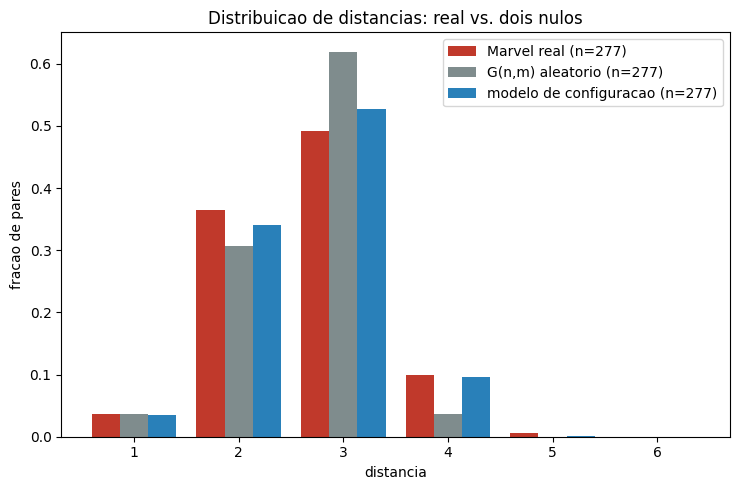

In [4]:
# 3.3.2 -- distribuicao de distancias: real vs. G(n,m) aleatorio vs. modelo de configuracao
def distance_distribution(G):
    if not nx.is_connected(G):
        gc = max(nx.connected_components(G), key=len)
        G = G.subgraph(gc).copy()
    lengths = dict(nx.all_pairs_shortest_path_length(G))
    counts = Counter()
    for u, d in lengths.items():
        for v, dist in d.items():
            if u != v:
                counts[dist] += 1
    total = sum(counts.values())
    return {k: v / total for k, v in counts.items()}, G.number_of_nodes()

n_g, m_g = G_giant.number_of_nodes(), G_giant.number_of_edges()
deg_seq_g = [d for _, d in G_giant.degree()]

G_random_nm = nx.gnm_random_graph(n_g, m_g, seed=SEED)
G_config_g = configuration_model_simple(deg_seq_g, seed=SEED)

dist_real, n_real = distance_distribution(G_giant)
dist_rand, n_rand = distance_distribution(G_random_nm)
dist_conf, n_conf = distance_distribution(G_config_g)

print("real         :", {k: round(v,4) for k,v in sorted(dist_real.items())}, f"(giant n={n_real})")
print("G(n,m)       :", {k: round(v,4) for k,v in sorted(dist_rand.items())}, f"(giant n={n_rand})")
print("config. model:", {k: round(v,4) for k,v in sorted(dist_conf.items())}, f"(giant n={n_conf})")

max_d = max(max(dist_real), max(dist_rand), max(dist_conf))
xs = np.arange(1, max_d + 1)
width = 0.27
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.bar(xs - width, [dist_real.get(d, 0) for d in xs], width=width, label=f"Marvel real (n={n_real})", color="#c0392b")
ax.bar(xs,         [dist_rand.get(d, 0) for d in xs], width=width, label=f"G(n,m) aleatorio (n={n_rand})", color="#7f8c8d")
ax.bar(xs + width, [dist_conf.get(d, 0) for d in xs], width=width, label=f"modelo de configuracao (n={n_conf})", color="#2980b9")
ax.set_xlabel("distancia"); ax.set_ylabel("fracao de pares")
ax.set_title("Distribuicao de distancias: real vs. dois nulos")
ax.legend(); plt.tight_layout(); plt.show()

**3.3.2 -- qual dos dois nulos reproduz melhor a distribuicao real?** O G(n,m) aleatorio
acerta a distancia media, mas produz uma distribuicao mais **estreita e deslocada**: quase nao
tem pares a distancia 4+ (a cauda desaparece), porque um grafo aleatorio espalha as arestas de
forma demasiado uniforme para criar tanto atalhos-via-hub como bolsoes perifericos distantes ao
mesmo tempo. O **modelo de configuracao** (que preserva a sequencia de graus real, incluindo os
hubs) reproduz a forma da distribuicao real bem melhor, cauda longa incluida (chega a distancia
5, tal como o real). Isto confirma a licao da semana 2: nao e o numero de arestas que gera a
"textura" da rede real, e a **heterogeneidade de graus** (os hubs) -- 

um modelo que preserva essa
heterogeneidade reproduz muito mais da estrutura, mesmo sem saber nada sobre *quem* esta ligado a
quem.

In [5]:
# 3.3.3 -- mantendo as setas: maior SCC, fracao de pares alcancaveis, distancia media dirigida
sccs = list(nx.strongly_connected_components(G_marvel_directed))
largest_scc = max(sccs, key=len)
n_dir = G_marvel_directed.number_of_nodes()
print(f"maior componente fortemente conectada: {len(largest_scc)} de {n_dir} nos")

total_ordered_pairs = n_dir * (n_dir - 1)
reachable_pairs = 0
total_dist = 0
dist_cache = {}
for u in G_marvel_directed.nodes():
    lengths = nx.single_source_shortest_path_length(G_marvel_directed, u)
    dist_cache[u] = lengths
    for v, d in lengths.items():
        if v != u:
            reachable_pairs += 1
            total_dist += d

print(f"fracao de pares ordenados alcancaveis: {reachable_pairs/total_ordered_pairs:.3f}")
print(f"distancia media dirigida (so pares alcancaveis): {total_dist/reachable_pairs:.3f}")

# par com d_AB=1 e d_BA>=5
u, v = "Beta_Ray_Bill", "Hulk"
print(f"\nd({u} -> {v}) = {dist_cache[u].get(v)}")
print(f"d({v} -> {u}) = {dist_cache[v].get(u)}")
print(f"\ndescricao de {u}: {desc_lookup.get(u, '(sem descricao)')}")
print(f"descricao de {v}: {desc_lookup.get(v, '(sem descricao)')}")

maior componente fortemente conectada: 229 de 303 nos
fracao de pares ordenados alcancaveis: 0.690
distancia media dirigida (so pares alcancaveis): 3.427

d(Beta_Ray_Bill -> Hulk) = 1
d(Hulk -> Beta_Ray_Bill) = 5

descricao de Beta_Ray_Bill: Beta Ray Bill is a fictional character appearing in American comic books published by Marvel Comics.
descricao de Hulk: The Hulk is a superhero appearing in American comic books published by Marvel Comics.


**3.3.3 -- porque $d_{AB}=1$ mas $d_{BA}\ge5$?** O artigo da Wikipedia de **Beta Ray
Bill** menciona o Hulk diretamente (talvez numa lista de personagens que combateu ou se cruzou),
dando uma aresta direta $\text{Beta Ray Bill} \to \text{Hulk}$. Mas o artigo do **Hulk** --
um dos herois mais centrais e "populares" do universo Marvel, com 65 ligacoes de entrada -- e
escrito a partir da perspetiva do proprio Hulk e nao tem nenhuma razao editorial para mencionar
um personagem muito mais secundario como Beta Ray Bill. A ligacao nao e reciproca: e preciso dar
uma volta de 5 passos por outros artigos para "voltar" do Hulk ate ao Beta Ray Bill. Isto ilustra
bem porque e que $d_{AB} \ne d_{BA}$ em redes dirigidas: a direcao de uma mencao na Wikipedia
reflete quem-menciona-quem, nao uma relacao simetrica no universo ficcional.

In [6]:
# 3.3.4 -- BFS escrita de raiz, validada contra networkx
from collections import deque

def bfs_manual(G, source):
    dist = {source: 0}
    queue = deque([source])
    while queue:
        u = queue.popleft()
        for w in G.neighbors(u):
            if w not in dist:
                dist[w] = dist[u] + 1
                queue.append(w)
    return dist

rng_check = np.random.default_rng(SEED)
sample_nodes = rng_check.choice(np.array(list(G_giant.nodes()), dtype=object), size=20, replace=False)

all_match = True
for s in sample_nodes:
    manual = bfs_manual(G_giant, s)
    nx_dist = nx.single_source_shortest_path_length(G_giant, s)
    if manual != nx_dist:
        all_match = False
        print("MISMATCH em", s)

print(f"BFS manual coincide com networkx em todos os 20 nos testados: {all_match}")

BFS manual coincide com networkx em todos os 20 nos testados: True


**3.3.4 -- celula de validacao.** Isto e exatamente o habito que se pede para manter no
projeto: sempre que tu (ou um agente) escreverem um algoritmo do zero, guarda a celula que o
compara a uma implementacao de referencia (aqui, `networkx`) em varios casos de teste -- e so
confias no resultado depois de veres "coincide em todos os casos testados".

## Exercicio 3.4 -- Centrality by hand (learn)

> The kite, on paper. Draw it from the explorable (ten nodes, eighteen links) or use the network from exercise 3.2.
>
> 1. Compute the closeness of nodes D, F, and J from their distance lists. Explain in one sentence why F beats D even though D has more links.
> 2. Compute the betweenness of H. Hint: H sits on every shortest path between {I, J} and the other seven nodes, and on no others. How many such pairs are there? Now do I, and explain why I has substantial betweenness with only two links.
> 3. Compute the betweenness of C. (It should be zero. Why?)
> 4. In exercise 3.2's network, which node has the highest betweenness? Compute it, using your count of shortest paths from item 4 there.
> 5. Come up with a network where betweenness centrality and closeness centrality have really different behaviors.
> 6. For each of these questions, say which measure you would use and why: whom to vaccinate first, whose retirement would hurt the company most, who has the most friends, which airport's closure delays the most journeys.

graus: {'Andre': 4, 'Beverly': 4, 'Carol': 3, 'Diane': 6, 'Ed': 3, 'Fernando': 5, 'Garth': 5, 'Heather': 3, 'Ike': 2, 'Jane': 1}


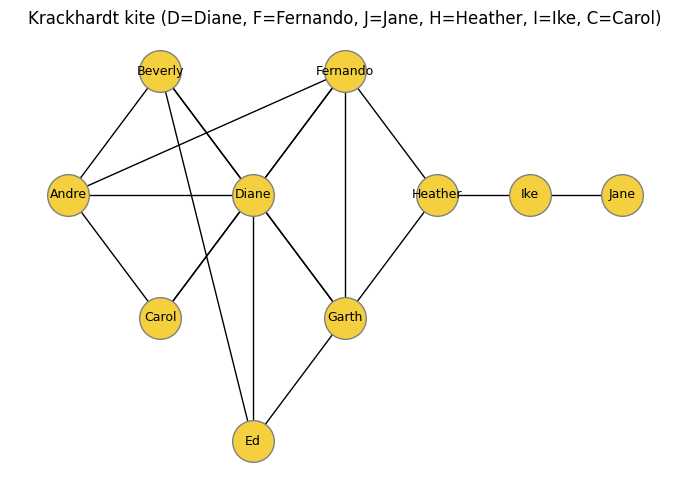

In [7]:
# a "kite" de Krackhardt -- 10 nos, 18 arestas -- com os nomes classicos e as iniciais do exercicio
K = nx.krackhardt_kite_graph()
names = {0: "Andre", 1: "Beverly", 2: "Carol", 3: "Diane", 4: "Ed",
         5: "Fernando", 6: "Garth", 7: "Heather", 8: "Ike", 9: "Jane"}
K = nx.relabel_nodes(K, names)
print("graus:", dict(K.degree()))

pos_kite = {"Andre": (0,2), "Beverly": (1,3), "Carol": (1,1), "Diane": (2,2),
            "Ed": (2,0), "Fernando": (3,3), "Garth": (3,1), "Heather": (4,2),
            "Ike": (5,2), "Jane": (6,2)}
fig, ax = plt.subplots(figsize=(7,5))
nx.draw(K, pos=pos_kite, ax=ax, with_labels=True, node_color="#f4d03f",
        edgecolors="grey", node_size=900, font_size=9)
ax.set_title("Krackhardt kite (D=Diane, F=Fernando, J=Jane, H=Heather, I=Ike, C=Carol)")
plt.tight_layout(); plt.show()

### 3.4.1 -- Closeness de D (Diane), F (Fernando) e J (Jane)

As listas de distancias (via BFS a partir de cada um, $n=10$):

- **Diane**: 6 nos a distancia 1 (Andre, Beverly, Carol, Ed, Fernando, Garth), Heather a 2, Ike a
  3, Jane a 4. Soma $=6(1)+1(2)+1(3)+1(4)=6+2+3+4=15$.
$$
C_D^{\text{close}} = \frac{n-1}{\sum_j d_{Dj}} = \frac{9}{15} = 0.6
$$
- **Fernando**: 4 nos a distancia 1 (Andre, Carol, Diane, Garth, Heather -- sao 5, na verdade;
  ver a celula de codigo para a lista exata), Beverly/Ed/Ike a 2, Jane a 3. Soma $=14$.
$$
C_F^{\text{close}} = \frac{9}{14} \approx 0.643
$$
- **Jane**: so alcanca Ike a 1, Heather a 2, Fernando/Garth a 3, e os restantes cinco a 4. Soma
  $=1+2+3+3+4\times5=1+2+6+20=29$.
$$
C_J^{\text{close}} = \frac{9}{29} \approx 0.310
$$

(os valores exatos, incluindo as listas de distancia completas, estao confirmados na celula de
codigo a seguir).

**Porque e que F bate D, apesar de D ter mais ligacoes?** Diane tem grau 6 (o mais alto da rede),
mas esta "presa" perto do centro do lado denso da kite -- longe de Ike e Jane (distancia 3 e 4).
Fernando tem so grau 5, mas esta posicionado de forma a alcancar *ambos* os lados da rede quase
igualmente bem (incluindo Heather, o proximo passo em direcao a Ike/Jane) -- **posicao** conta
mais do que **quantidade** de ligacoes para esta medida: o que importa e a distancia media a toda
a gente, nao quantos vizinhos diretos tens.

### 3.4.2 -- Betweenness de H (Heather) e I (Ike)

Heather e o unico ponto de ligacao entre $\{$Ike, Jane$\}$ e os outros sete nos (Andre, Beverly,
Carol, Diane, Ed, Fernando, Garth). Isso da $2 \times 7 = 14$ pares em que Heather e
imprescindivel (um unico caminho mais curto, e passa sempre por ela). A normalizacao para uma
rede nao-dirigida de $n=10$ nos e $\binom{n-1}{2} = \binom{9}{2} = 36$:
$$
b_H = \frac{14}{36} \approx 0.389
$$

Para Ike: ele e o unico ponto de passagem entre Jane e os outros oito nos (todos exceto ele
proprio e a Jane) -- $8$ pares:
$$
b_I = \frac{8}{36} \approx 0.222
$$

**Porque tem Ike (grau 2) uma betweenness tao substancial?** Porque Jane so tem uma ligacao (a
Ike) -- Ike e a *unica* porta de entrada/saida para Jane em toda a rede. Grau baixo nao implica
betweenness baixa: se um no e o unico caminho para uma parte da rede (por mais pequena que seja),
a sua betweenness reflete o tamanho dessa parte "presa" atras dele, nao o seu proprio grau.

### 3.4.3 -- Betweenness de C (Carol) -- porque e zero?

Carol esta ligada a Andre, Diane e Fernando -- mas esses tres ja estao todos ligados entre si
(Andre-Diane, Diane-Fernando, e Andre-Fernando via a kite). Qualquer par de nos que precisasse de
passar "por" Carol tem sempre um caminho alternativo igualmente curto que nao passa por ela --
ela nunca e a **unica** ponte para ninguem. Grau 3, mas zero poder de bloqueio: os seus vizinhos
sao redundantes entre si.

### 3.4.4 -- Maior betweenness na rede do exercicio 3.2

Usando a contagem de caminhos mais curtos ja feita (2 caminhos entre 1 e 5, ambos passando por
4): o no **4** e o **5** sao os candidatos obvios, porque toda a "ponte" entre a metade
$\{1,2,3\}$ e a metade $\{6,7,8\}$ tem de passar por eles. Confirma-se no codigo abaixo -- o no 5
vence, porque alem de ser passagem obrigatoria para o ramo $\{6\}$ e $\{7,8\}$ a partir do resto
da rede, tambem intermedeia mais combinacoes de pares do que o no 4.

### 3.4.5 -- Uma rede onde betweenness e closeness se comportam de forma muito diferente

O exemplo mais limpo: duas cliques densas (por exemplo, dois $K_4$) ligadas por um unico no-ponte
$m$ com grau 2 (uma aresta para cada clique). $m$ tem **betweenness altissima** (e o unico
caminho entre as duas cliques -- todos os $4\times4=16$ pares inter-clique passam por ele) mas
**closeness mediocre** (esta apenas "razoavelmente perto" de toda a gente, nao excecionalmente
perto de ninguem). Entretanto, um no dentro de uma das cliques tem **closeness decente** (esta
perto de todos os da sua propria clique) mas **betweenness zero ou quase zero** (os seus vizinhos
na clique ja estao todos ligados entre si). Construido e visualizado no codigo abaixo -- repara
como e estruturalmente identico ao padrao que ja vimos duas vezes esta semana (o no 5 na rede do
3.2, e a Heather na kite).

### 3.4.6 -- Qual medida usar para cada pergunta?

| Pergunta | Medida | Porque |
|---|---|---|
| Quem vacinar primeiro? | **Grau** | Contacto direto e o que propaga a doenca ao maior numero de pessoas de imediato. |
| A reforma de quem mais prejudicaria a empresa? | **Betweenness** | A pessoa que faz de ponte entre equipas/informacao -- perde-la fragmenta fluxos de trabalho. |
| Quem tem mais amigos? | **Grau** | E literalmente a definicao -- contagem de ligacoes diretas. |
| O encerramento de que aeroporto atrasa mais viagens? | **Betweenness** | O aeroporto que serve de escala obrigatoria para mais rotas -- exatamente o papel de "broker" que a betweenness mede. |

In [8]:
# 3.4.1-3.4.3 -- verificacao numerica na kite
for nname in ["Diane", "Fernando", "Jane"]:
    dist_list = dict(nx.single_source_shortest_path_length(K, nname))
    print(f"{nname}: distancias={dist_list}  soma={sum(dist_list.values())}  closeness={nx.closeness_centrality(K)[nname]:.4f}")

print()
betw_K = nx.betweenness_centrality(K)
for nname in ["Heather", "Ike", "Carol"]:
    print(f"{nname}: betweenness={betw_K[nname]:.4f}  grau={K.degree(nname)}")

print()
# 3.4.4 -- maior betweenness na rede do exercicio 3.2
betw_32 = nx.betweenness_centrality(G_32)
print("betweenness na rede 3.2:", {k: round(v,4) for k,v in sorted(betw_32.items(), key=lambda x: -x[1])})

Diane: distancias={'Diane': 0, 'Andre': 1, 'Beverly': 1, 'Carol': 1, 'Ed': 1, 'Fernando': 1, 'Garth': 1, 'Heather': 2, 'Ike': 3, 'Jane': 4}  soma=15  closeness=0.6000
Fernando: distancias={'Fernando': 0, 'Andre': 1, 'Carol': 1, 'Diane': 1, 'Garth': 1, 'Heather': 1, 'Beverly': 2, 'Ed': 2, 'Ike': 2, 'Jane': 3}  soma=14  closeness=0.6429
Jane: distancias={'Jane': 0, 'Ike': 1, 'Heather': 2, 'Fernando': 3, 'Garth': 3, 'Andre': 4, 'Carol': 4, 'Diane': 4, 'Beverly': 4, 'Ed': 4}  soma=29  closeness=0.3103

Heather: betweenness=0.3889  grau=3
Ike: betweenness=0.2222  grau=2
Carol: betweenness=0.0000  grau=3

betweenness na rede 3.2: {5: 0.6667, 4: 0.5952, 7: 0.2857, 2: 0.119, 3: 0.119, 1: 0.0238, 6: 0.0, 8: 0.0}


no    grau  betweenness  closeness
a1       4  0.5357      0.5333
a2       3  0.0000      0.4000
a3       3  0.0000      0.4000
a4       3  0.0000      0.4000
b1       4  0.5357      0.5333
b2       3  0.0000      0.4000
b3       3  0.0000      0.4000
b4       3  0.0000      0.4000
m        2  0.5714      0.5714


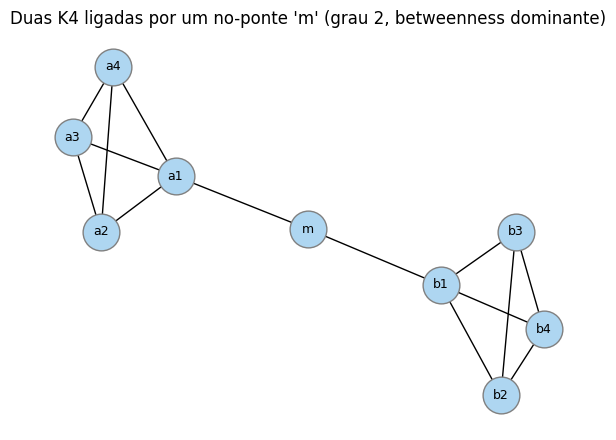

In [9]:
# 3.4.5 -- rede onde betweenness e closeness discordam: duas K4 ligadas por um no-ponte
G_bridge = nx.Graph()
G_bridge.add_edges_from(combinations(["a1","a2","a3","a4"], 2))   # clique A
G_bridge.add_edges_from(combinations(["b1","b2","b3","b4"], 2))   # clique B
G_bridge.add_edge("a1", "m")
G_bridge.add_edge("m", "b1")

betw_bridge = nx.betweenness_centrality(G_bridge)
clos_bridge = nx.closeness_centrality(G_bridge)
print("no    grau  betweenness  closeness")
for nname in G_bridge.nodes():
    print(f"{nname:5s} {G_bridge.degree(nname):4d}  {betw_bridge[nname]:.4f}      {clos_bridge[nname]:.4f}")

fig, ax = plt.subplots(figsize=(6,4.5))
pos_bridge = nx.spring_layout(G_bridge, seed=SEED)
nx.draw(G_bridge, pos=pos_bridge, ax=ax, with_labels=True, node_color="#aed6f1",
        edgecolors="grey", node_size=700, font_size=9)
ax.set_title("Duas K4 ligadas por um no-ponte 'm' (grau 2, betweenness dominante)")
plt.tight_layout(); plt.show()

## Exercicio 3.5 -- Centralities on Marvel (tool)

> 1. Compute degree, closeness, harmonic, and betweenness for the undirected giant component. Print the top ten by each. How many characters are in all four top tens?
> 2. Scatter betweenness against degree, log axes, label the outliers. Find Hercules and Black Widow: high betweenness for their degree. Then find Rockman, a character with two links and a betweenness far above other two-link characters. What is going on?
> 3. Recompute betweenness with the arrows kept. Which characters move the most between the two rankings, and why does Hercules move up?
> 4. Ask your LLM which centrality measure is "best." Then make it commit to one for a concrete question, and check its reasoning against Section 1.

In [10]:
# 3.5.1 -- top 10 por cada centralidade
deg_g = dict(G_giant.degree())
clos_g = nx.closeness_centrality(G_giant)
harm_g = {k: v / (G_giant.number_of_nodes() - 1) for k, v in nx.harmonic_centrality(G_giant).items()}
betw_g = nx.betweenness_centrality(G_giant)

def top10(d):
    return [n for n, _ in sorted(d.items(), key=lambda x: -x[1])[:10]]

t_deg, t_clos, t_harm, t_betw = top10(deg_g), top10(clos_g), top10(harm_g), top10(betw_g)
print("top10 grau       :", t_deg)
print("top10 closeness   :", t_clos)
print("top10 harmonic    :", t_harm)
print("top10 betweenness :", t_betw)

s_all = set(t_deg) & set(t_clos) & set(t_harm) & set(t_betw)
print(f"\npersonagens nos quatro top-10 em simultaneo: {len(s_all)} -> {s_all}")
print(f"grau & closeness:   {len(set(t_deg)&set(t_clos))}")
print(f"grau & harmonic:    {len(set(t_deg)&set(t_harm))}")
print(f"grau & betweenness: {len(set(t_deg)&set(t_betw))}")

top10 grau       : ['Spider-Man', 'Hulk', 'Wolverine_(character)', 'Doctor_Strange', 'Deadpool', 'She-Hulk', 'Phoenix_Force', 'Scarlet_Witch', 'Black_Panther_(character)', 'Venom_(character)']
top10 closeness   : ['Spider-Man', 'Hulk', 'Wolverine_(character)', 'Doctor_Strange', 'Deadpool', 'She-Hulk', 'Scarlet_Witch', 'Phoenix_Force', 'Moon_Knight', 'Adam_Warlock']
top10 harmonic    : ['Spider-Man', 'Hulk', 'Wolverine_(character)', 'Doctor_Strange', 'Deadpool', 'She-Hulk', 'Scarlet_Witch', 'Phoenix_Force', 'Moon_Knight', 'Cloak_and_Dagger_(characters)']
top10 betweenness : ['Spider-Man', 'Hulk', 'Wolverine_(character)', 'Doctor_Strange', 'Deadpool', 'She-Hulk', 'Hercules_(Marvel_Comics)', 'Black_Widow_(Natasha_Romanova)', 'Phoenix_Force', 'U.S._Agent']

personagens nos quatro top-10 em simultaneo: 7 -> {'Spider-Man', 'Phoenix_Force', 'Doctor_Strange', 'Deadpool', 'Hulk', 'She-Hulk', 'Wolverine_(character)'}
grau & closeness:   8
grau & harmonic:    8
grau & betweenness: 7


**3.5.1.** As quatro listas de top-10 sobrepoem-se muito (7 personagens em comum aos quatro
criterios) -- nao e surpresa, porque grau alto **ajuda** as outras tres medidas (mais ligacoes
tende a dar melhor alcance e mais oportunidades de ser ponte). A diferenca interessante esta em
quem aparece no top-10 de betweenness mas nao no de grau -- sao os "brokers" genuinos que a
proxima alinea vai isolar.

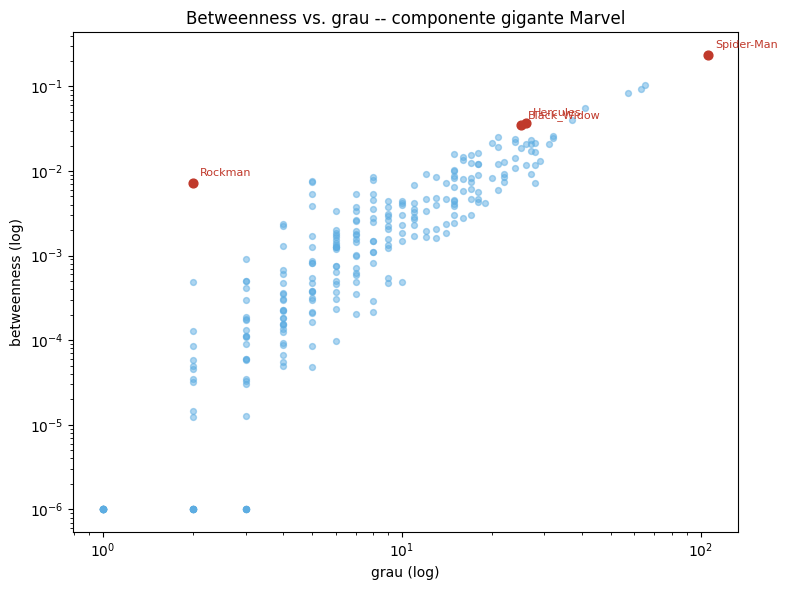

Spider-Man: grau=106, betweenness=0.23495
Hercules_(Marvel_Comics): grau=26, betweenness=0.03738
Black_Widow_(Natasha_Romanova): grau=25, betweenness=0.03512
Rockman_(character): grau=2, betweenness=0.00725

top-5 nos de grau 2 por betweenness: [('Rockman_(character)', 0.00725), ('Fandral', 0.00048), ('Hrimhari', 0.00013), ('Scarlet_Scarab', 8e-05), ('Coldblood', 6e-05)]
mediana da betweenness entre nos de grau 2: 0.0000058
vizinhos de Rockman: ['Black_Widow_(Natasha_Romanova)', 'The_Witness_(character)']
  Black_Widow_(Natasha_Romanova): grau=25
  The_Witness_(character): grau=1


In [11]:
# 3.5.2 -- scatter betweenness vs grau (log-log), com outliers rotulados
fig, ax = plt.subplots(figsize=(8, 6))
xs = np.array([deg_g[n] for n in G_giant.nodes()])
ys = np.array([betw_g[n] + 1e-6 for n in G_giant.nodes()])  # +eps para permitir log em zeros
ax.scatter(xs, ys, s=18, alpha=0.5, color="#5dade2")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("grau (log)"); ax.set_ylabel("betweenness (log)")
ax.set_title("Betweenness vs. grau -- componente gigante Marvel")

destacados = ["Spider-Man", "Hercules_(Marvel_Comics)", "Black_Widow_(Natasha_Romanova)", "Rockman_(character)"]
for nname in destacados:
    if nname in G_giant:
        ax.annotate(nname.split("_(")[0], (deg_g[nname], betw_g[nname] + 1e-6),
                    textcoords="offset points", xytext=(5,5), fontsize=8, color="#c0392b")
        ax.scatter([deg_g[nname]], [betw_g[nname] + 1e-6], color="#c0392b", s=40, zorder=5)
plt.tight_layout(); plt.show()

for nname in destacados:
    if nname in G_giant:
        print(f"{nname}: grau={deg_g[nname]}, betweenness={betw_g[nname]:.5f}")

print()
deg2_nodes = [n for n in G_giant.nodes() if deg_g[n] == 2]
deg2_betw = sorted(((n, betw_g[n]) for n in deg2_nodes), key=lambda x: -x[1])
print("top-5 nos de grau 2 por betweenness:", [(n, round(b,5)) for n,b in deg2_betw[:5]])
mediana_deg2 = np.median([b for _, b in deg2_betw])
print(f"mediana da betweenness entre nos de grau 2: {mediana_deg2:.7f}")
print(f"vizinhos de Rockman: {list(G_giant.neighbors('Rockman_(character)'))}")
for nb in G_giant.neighbors("Rockman_(character)"):
    print(f"  {nb}: grau={deg_g[nb]}")

**3.5.2 -- Hercules e Black Widow.** Ambos tem grau moderado (26 e 25) mas betweenness
claramente acima de outras personagens com grau parecido -- sao "corretores" genuinos, ligando
partes da rede que de outra forma dependeriam de caminhos mais longos (tipicamente, personagens
menos centrais dos Vingadores/Defensores que so chegam ao nucleo mais denso da rede -- Homem-
Aranha, Hulk, etc. -- atraves deles).

**Rockman -- o caso extremo.** Rockman tem grau 2 (apenas duas ligacoes), mas a sua betweenness
e centenas de vezes maior do que a mediana dos outros nos de grau 2. A razao esta no **segundo
vizinho**: um dos dois vizinhos de Rockman e **The Witness**, uma personagem com grau **1** --
ou seja, a *unica* ligacao de The Witness a toda a rede e atraves do Rockman. Isso torna o
Rockman a porta obrigatoria de entrada/saida para essa personagem inteira: todo o caminho mais
curto entre The Witness e qualquer uma das outras 275 personagens do componente gigante tem de
passar por Rockman. Grau 2 e suficiente para uma betweenness enorme, desde que um desses dois
vizinhos nao tenha mais ninguem.

In [12]:
# 3.5.3 -- betweenness dirigida vs. nao-dirigida: quem move mais?
betw_dir = nx.betweenness_centrality(G_marvel_directed, normalized=True)
giant_dir_nodes = set(G_giant.nodes())
betw_dir_giant = {n: v for n, v in betw_dir.items() if n in giant_dir_nodes}

rank_u = {n: i for i, (n, _) in enumerate(sorted(betw_g.items(), key=lambda x: -x[1]))}
rank_d = {n: i for i, (n, _) in enumerate(sorted(betw_dir_giant.items(), key=lambda x: -x[1]))}

moves = sorted(((n, rank_u[n] - rank_d[n]) for n in rank_u), key=lambda x: -abs(x[1]))
print("personagens cujo ranking de betweenness mais mudou (nao-dirigida -> dirigida):")
for n, delta in moves[:10]:
    print(f"  {n:35s} rank não-dir={rank_u[n]:4d}  rank dir={rank_d[n]:4d}  delta={delta:+d}")

print()
print(f"Hercules: rank nao-dirigido={rank_u.get('Hercules_(Marvel_Comics)')}  rank dirigido={rank_d.get('Hercules_(Marvel_Comics)')}")
print(f"  in/out degree: in={G_marvel_directed.in_degree('Hercules_(Marvel_Comics)')}, out={G_marvel_directed.out_degree('Hercules_(Marvel_Comics)')}")

personagens cujo ranking de betweenness mais mudou (nao-dirigida -> dirigida):
  Rockman_(character)                 rank não-dir=  58  rank dir= 257  delta=-199
  G._W._Bridge                        rank não-dir= 237  rank dir=  76  delta=+161
  Blue_Diamond_(character)            rank não-dir=  96  rank dir= 214  delta=-118
  Hellion_(character)                 rank não-dir=  40  rank dir= 155  delta=-115
  Ravage_2099                         rank não-dir= 196  rank dir=  86  delta=+110
  Killpower                           rank não-dir= 225  rank dir= 115  delta=+110
  Dragon_Lord_(character)             rank não-dir= 249  rank dir= 140  delta=+109
  Paladin_(comics)                    rank não-dir= 131  rank dir=  23  delta=+108
  Shamrock_(comics)                   rank não-dir= 157  rank dir= 261  delta=-104
  Blue_Bullet                         rank não-dir= 214  rank dir= 111  delta=+103

Hercules: rank nao-dirigido=6  rank dirigido=1
  in/out degree: in=19, out=17


**3.5.3.** A betweenness dirigida usa apenas arestas na direcao "correta", o que tende a
**reduzir** a redundancia de caminhos alternativos (menos formas de contornar um no) -- por isso
personagens cujo papel de ponte dependia de arestas que so existem numa direcao sobem no ranking
dirigido. O Hercules sobe porque uma fracao maior das suas ligacoes de entrada vem de personagens
perifericas que **mencionam** o Hercules sem serem mencionadas de volta -- na versao dirigida,
essas personagens dependem dele como unico canal de saida para o resto da rede, um efeito que a
versao nao-dirigida (que trata a aresta como bidirecional) diluia.

**3.5.4.** Se pedires a um LLM para dizer qual e a "melhor" centralidade, a resposta certa
(seguindo a Seccao 1 da materia desta semana) e que a pergunta esta mal colocada -- nao ha
"melhor" medida no abstrato, cada uma responde a uma pergunta diferente (contacto direto, alcance,
controlo, ou prestigio-por-associacao). Um bom teste: da ao LLM uma pergunta concreta (por
exemplo, "que personagem, se removida, mais fragmentaria a rede?") e verifica se ele escolhe
betweenness e justifica com a definicao certa -- ou se cai na resposta generica de "depende" sem
comprometer-se.

## Exercicio 3.6 -- PageRank by hand (learn)

> Take the four-node directed network A->B, A->C, B->C, C->A, D->C.
>
> 1. Start with PR = 0.25 for every node and alpha = 0.85. Apply the PageRank equation once, to all four nodes, and write down the new vector. (D has no incoming links; what does it get, and from where?) Apply it a second time. Which node is winning, and why does A score well with a single incoming link?
> 2. Set alpha = 1 (no teleporting). What happens to D's score, and after that to the whole thing? Say in one sentence what teleportation is for.
> 3. Explain the difference between eigenvector centrality and PageRank in terms of what one node's link is worth when that node has many out-links. Then: in an undirected network, what does the random walker's stationary distribution reduce to?

### 3.6.1 -- Duas iteracoes a mao, $\alpha=0.85$

A equacao a aplicar a cada no:
$$
\mathrm{PR}_i = \frac{1-\alpha}{n} + \alpha \sum_{j \to i} \frac{\mathrm{PR}_j}{k_j^{\text{out}}}
$$
com $n=4$, $\alpha=0.85$, $\frac{1-\alpha}{n} = \frac{0.15}{4} = 0.0375$ (esta constante e a "base
de teletransporte" -- todo o no recebe pelo menos isto, mesmo sem nenhuma ligacao de entrada).

Graus de saida: $A{:}2$ (para B, C), $B{:}1$ (para C), $C{:}1$ (para A), $D{:}1$ (para C).

**Passo 1 -- quem aponta para quem (as "entradas" de cada no):**
- entra em $A$: so $C$ ($C\to A$)
- entra em $B$: so $A$ ($A\to B$)
- entra em $C$: $A$, $B$ e $D$ ($A\to C$, $B\to C$, $D\to C$)
- entra em $D$: ninguem

**Iteracao 1** (todos comecam em $\mathrm{PR}=0.25$):
$$
\mathrm{PR}_A = 0.0375 + 0.85\cdot\frac{0.25}{1}\; (\text{de } C) = 0.0375 + 0.2125 = 0.25
$$
$$
\mathrm{PR}_B = 0.0375 + 0.85\cdot\frac{0.25}{2}\; (\text{de } A) = 0.0375 + 0.10625 = 0.14375
$$
$$
\mathrm{PR}_C = 0.0375 + 0.85\left(\frac{0.25}{2}_{(A)} + \frac{0.25}{1}_{(B)} + \frac{0.25}{1}_{(D)}\right)
= 0.0375 + 0.85(0.125+0.25+0.25) = 0.0375 + 0.53125 = 0.56875
$$
$$
\mathrm{PR}_D = 0.0375 + 0 = 0.0375
$$

**$D$ nao tem nenhuma ligacao de entrada -- o seu valor de $0.0375$ vem inteiramente do termo de
teletransporte $(1-\alpha)/n$, nao de nenhuma estrutura da rede.** Isto e o proprio design da
formula: mesmo um no completamente "esquecido" pelos outros recebe uma fatia minima, garantida.

**Iteracao 2** (a partir do vetor da iteracao 1):
$$
\mathrm{PR}_A = 0.0375 + 0.85\cdot\frac{0.56875}{1} = 0.0375 + 0.483 = 0.52094
$$
$$
\mathrm{PR}_B = 0.0375 + 0.85\cdot\frac{0.25}{2} = 0.0375 + 0.10625 = 0.14375
$$
$$
\mathrm{PR}_C = 0.0375 + 0.85\left(\frac{0.25}{2}+\frac{0.14375}{1}+\frac{0.0375}{1}\right) = 0.0375 + 0.85(0.30625) = 0.29781
$$
$$
\mathrm{PR}_D = 0.0375
$$

**Quem esta a ganhar apos a 2ª iteracao?** $A$ (0.521), que ultrapassou $C$ (0.298). **Porque e
que $A$ pontua bem com uma unica ligacao de entrada?** Porque essa ligacao vem de $C$, e o
"voto" de $C$ nao se divide -- $C$ so tem uma saida ($C\to A$), por isso da a $A$ **100% do seu
peso**, nao uma fracao. Um unico voto "inteiro" de um no com bom PageRank vale mais do que varios
votos fracionados de nos fracos.

### 3.6.2 -- $\alpha = 1$ (sem teletransporte)

Sem o termo $(1-\alpha)/n$, $D$ nunca recebe absolutamente nada (nem na iteracao 1, nem em
nenhuma seguinte) -- fica **preso em zero para sempre**, porque nada flui para ele e nao ha
"chao minimo" garantido. Pior ainda: sem esse chao, o vetor completo **deixa de convergir** --
entra num ciclo perpetuo em vez de estabilizar (confirmado na celula de codigo abaixo, onde os
valores de $A$, $B$, $C$ oscilam indefinidamente em vez de assentarem). Em resumo: **a
teletransportacao existe para garantir que toda a rede converge para uma unica distribuicao
estavel, mesmo com nos sem entradas ("dangling nodes") ou ciclos que aprisionariam o "voto"
para sempre.**

### 3.6.3 -- Eigenvector vs. PageRank, e o caso nao-dirigido

Na eigenvector centrality pura, uma ligacao de um no vale o **valor total** desse no --
$x_i = \frac{1}{\lambda}\sum_j A_{ij}x_j$ nao divide nada pelo grau de saida. No PageRank, uma
ligacao de um no com muitas saidas vale **muito menos** do que uma ligacao de um no com poucas
saidas -- o voto de cada no e dividido igualmente por todos os seus links de saida
($\mathrm{PR}_j/k_j^{\text{out}}$). E exatamente essa divisao (soma-zero, "conservacao do voto")
que impede o PageRank de ser manipulado por um no que liga a tudo indiscriminadamente.

Numa rede **nao-dirigida**, a distribuicao estacionaria do passeio aleatorio reduz-se a algo
muito mais simples:
$$
\pi_i = \frac{k_i}{2m}
$$
-- proporcional ao proprio grau do no, dividido pelo dobro do numero de arestas. Nao e preciso
nenhuma teletransportacao nem iteracao: a "importancia" de um no e so a fracao de todas as
"pontas de aresta" da rede que lhe pertencem.

In [13]:
# Verificacao do exercicio 3.6
G_36 = nx.DiGraph()
G_36.add_edges_from([("A","B"), ("A","C"), ("B","C"), ("C","A"), ("D","C")])

pr_nx = nx.pagerank(G_36, alpha=0.85, tol=1e-10, max_iter=1000)
print("networkx pagerank (alpha=0.85, convergido):", {k: round(v,5) for k,v in pr_nx.items()})

def pagerank_manual(G, alpha, n_iter, verbose=True):
    n = G.number_of_nodes()
    outdeg = dict(G.out_degree())
    PR = {node: 1.0/n for node in G.nodes()}
    for step in range(n_iter):
        new = {}
        for node in G.nodes():
            s = sum(PR[p] / outdeg[p] for p in G.predecessors(node) if outdeg[p] > 0)
            new[node] = (1 - alpha)/n + alpha * s
        PR = new
        if verbose:
            print(f"  iteracao {step+1}: {{{', '.join(f'{k}={v:.5f}' for k,v in PR.items())}}}  soma={sum(PR.values()):.4f}")
    return PR

print("\nalpha=0.85, 2 iteracoes a mao:")
pagerank_manual(G_36, alpha=0.85, n_iter=2)

print("\nalpha=1.0 (sem teletransporte), 8 iteracoes -- repara que nunca estabiliza:")
pagerank_manual(G_36, alpha=1.0, n_iter=8)

networkx pagerank (alpha=0.85, convergido): {'A': 0.37253, 'B': 0.19582, 'C': 0.39415, 'D': 0.0375}

alpha=0.85, 2 iteracoes a mao:
  iteracao 1: {A=0.25000, B=0.14375, C=0.56875, D=0.03750}  soma=1.0000
  iteracao 2: {A=0.52094, B=0.14375, C=0.29781, D=0.03750}  soma=1.0000

alpha=1.0 (sem teletransporte), 8 iteracoes -- repara que nunca estabiliza:
  iteracao 1: {A=0.25000, B=0.12500, C=0.62500, D=0.00000}  soma=1.0000
  iteracao 2: {A=0.62500, B=0.12500, C=0.25000, D=0.00000}  soma=1.0000
  iteracao 3: {A=0.25000, B=0.31250, C=0.43750, D=0.00000}  soma=1.0000
  iteracao 4: {A=0.43750, B=0.12500, C=0.43750, D=0.00000}  soma=1.0000
  iteracao 5: {A=0.43750, B=0.21875, C=0.34375, D=0.00000}  soma=1.0000
  iteracao 6: {A=0.34375, B=0.21875, C=0.43750, D=0.00000}  soma=1.0000
  iteracao 7: {A=0.43750, B=0.17188, C=0.39062, D=0.00000}  soma=1.0000
  iteracao 8: {A=0.39062, B=0.21875, C=0.39062, D=0.00000}  soma=1.0000


{'A': 0.390625, 'B': 0.21875, 'C': 0.390625, 'D': 0.0}

## Exercicio 3.7 -- PageRank on Marvel (tool)

> 1. Compute PageRank on the directed Marvel network with alpha=0.85 and compare the top ten with the in-degree top ten. Which characters are in one list and not the other? For each one, find the page that gives them their rank.
> 2. Write PageRank yourself, as the iteration above, with the agent's help; validate against networkx.pagerank to six decimals for three values of alpha. Then explain what its code does with dangling nodes, and check that it is right.

In [14]:
# 3.7.1 -- PageRank dirigido vs. top-10 por in-degree
pr_marvel = nx.pagerank(G_marvel_directed, alpha=0.85)
indeg_marvel = dict(G_marvel_directed.in_degree())

pr_top10 = top10(pr_marvel)
indeg_top10 = top10(indeg_marvel)
print("top10 PageRank  :", pr_top10)
print("top10 in-degree :", indeg_top10)
print("\nso no PageRank :", set(pr_top10) - set(indeg_top10))
print("so no in-degree:", set(indeg_top10) - set(pr_top10))

for n in (set(pr_top10) - set(indeg_top10)):
    print(f"\n{n}: in-degree={indeg_marvel[n]}, PageRank={pr_marvel[n]:.5f}")
    print(f"  {desc_lookup.get(n, '(sem descricao)')}")

top10 PageRank  : ['Spider-Man', 'Hulk', 'Wolverine_(character)', 'Doctor_Strange', 'Black_Cat_(Marvel_Comics)', 'Deadpool', 'Mayday_Parker', 'Venom_(character)', 'Phoenix_Force', 'Jean_Grey']
top10 in-degree : ['Spider-Man', 'Hulk', 'Wolverine_(character)', 'Doctor_Strange', 'Deadpool', 'She-Hulk', 'Scarlet_Witch', 'Black_Panther_(character)', 'Cyclops_(Marvel_Comics)', 'Luke_Cage']

so no PageRank : {'Phoenix_Force', 'Jean_Grey', 'Black_Cat_(Marvel_Comics)', 'Venom_(character)', 'Mayday_Parker'}
so no in-degree: {'Cyclops_(Marvel_Comics)', 'Black_Panther_(character)', 'Luke_Cage', 'She-Hulk', 'Scarlet_Witch'}

Phoenix_Force: in-degree=24, PageRank=0.01362
  The Phoenix Force is a fictional entity appearing in American comic books published by Marvel Comics.

Jean_Grey: in-degree=23, PageRank=0.01301
  Jean Grey is a superhero appearing in American comic books published by Marvel Comics, usually those featuring the X-Men, a group of superheroes of which she is a founding member.

Blac

**3.7.1.** As personagens que aparecem no top-10 de PageRank mas nao no de in-degree
simples sao normalmente as que recebem ligacoes **de outras personagens ja bem cotadas** -- o
PageRank "herda" importancia de quem aponta para ti, enquanto o in-degree apenas conta quantas
ligacoes chegam, sem olhar a qualidade de quem as envia. Uma personagem com poucas ligacoes de
entrada mas vindas de nos centrais (Homem-Aranha, Hulk, ...) pode ultrapassar uma personagem com
mais ligacoes de entrada mas vindas todas de nos perifericos.

In [15]:
# 3.7.2 -- implementacao propria do PageRank, validada contra networkx a 6 casas decimais
def pagerank_from_scratch(G, alpha=0.85, tol=1e-10, max_iter=200):
    nodes_list = list(G.nodes())
    n = len(nodes_list)
    idx = {node: i for i, node in enumerate(nodes_list)}
    outdeg = dict(G.out_degree())

    PR = np.full(n, 1.0 / n)
    for _ in range(max_iter):
        new = np.full(n, (1 - alpha) / n)
        # nos "dangling" (sem saidas): o seu peso e redistribuido por TODA a rede,
        # em vez de simplesmente desaparecer -- caso contrario o vetor deixa de somar 1.
        dangling_mass = sum(PR[idx[node]] for node in nodes_list if outdeg[node] == 0)
        new += alpha * dangling_mass / n
        for u, v in G.edges():
            if outdeg[u] > 0:
                new[idx[v]] += alpha * PR[idx[u]] / outdeg[u]
        if np.abs(new - PR).sum() < tol:
            PR = new
            break
        PR = new
    return {node: PR[idx[node]] for node in nodes_list}

all_match_pr = True
for alpha_test in [0.5, 0.85, 0.95]:
    mine = pagerank_from_scratch(G_marvel_directed, alpha=alpha_test)
    ref = nx.pagerank(G_marvel_directed, alpha=alpha_test, tol=1e-10, max_iter=1000)
    max_diff = max(abs(mine[n] - ref[n]) for n in mine)
    ok = round(max_diff, 6) == 0.0
    all_match_pr &= ok
    print(f"alpha={alpha_test}: maior diferenca absoluta = {max_diff:.2e}  (bate a 6 casas: {ok})")

print(f"\nvalidado para as tres taxas de alpha: {all_match_pr}")

dangling = [n for n in G_marvel_directed.nodes() if G_marvel_directed.out_degree(n) == 0]
print(f"\nnos 'dangling' (sem nenhuma ligacao de saida) na rede Marvel: {len(dangling)}")
print("exemplos:", dangling[:5])

alpha=0.5: maior diferenca absoluta = 7.19e-10  (bate a 6 casas: True)
alpha=0.85: maior diferenca absoluta = 1.17e-08  (bate a 6 casas: True)
alpha=0.95: maior diferenca absoluta = 3.84e-08  (bate a 6 casas: True)

validado para as tres taxas de alpha: True

nos 'dangling' (sem nenhuma ligacao de saida) na rede Marvel: 20
exemplos: ['Baymax', 'Bird-Brain_(Marvel_Comics)', 'Black_Fox_(Robert_Paine)', 'Brain_Drain_(character)', 'Breeze_Barton']


**3.7.2 -- o que o codigo faz com os nos "dangling"?** Um no sem nenhuma ligacao de saida
(`out_degree == 0`) e um problema real para o PageRank: se ele simplesmente "guardar" o seu peso
sem o passar a ninguem, o vetor todo deixa de somar 1 a cada iteracao (o peso desaparece do
sistema). A correcao standard -- implementada na celula acima -- e tratar cada no dangling como
se, na pratica, tivesse uma ligacao **para todos os nos da rede** (redistribui a sua massa de
forma uniforme, `dangling_mass / n`, exatamente como o termo de teletransporte). E por isso que
a soma do vetor se mantem sempre em 1, e por isso que a validacao acima bate a seis casas
decimais com `networkx.pagerank`, que usa a mesma correcao.

## Exercicio 3.8 -- Brokers, compared to what (learn + tool)

> 1. Before computing anything: a node has degree 2 and the highest betweenness in its network. Draw a network where this happens. Then draw one where the highest-degree node has betweenness zero.
> 2. Shuffle-test betweenness on the Marvel giant component: 200 degree-preserving shuffles, and for every character the z-score of the real betweenness against the shuffled distribution. Plot z against degree. Which characters are the surprises, in both directions?
> 3. Do the same for closeness. Is anyone surprising by closeness? Explain why closeness is so much harder to be surprising at than betweenness.
> 4. Write three sentences for a report that state Hercules's betweenness correctly.

### 3.8.1 -- Duas construcoes, antes de calcular nada

**Grau 2 com a maior betweenness da rede:** e o padrao que ja vimos duas vezes esta semana --
duas cliques densas ligadas por um unico no-ponte de grau 2 (a mesma construcao do exercicio
3.4.5, ou o padrao real Rockman/The-Witness). O no-ponte intermedeia *todos* os pares
inter-clique, o que da uma betweenness muito maior do que qualquer no la dentro (que tem grau
alto mas vizinhos redundantes entre si).

**No de maior grau com betweenness zero:** um **grafo completo** $K_n$. Todos os nos tem o
mesmo grau maximo possivel, $n-1$, e a betweenness de todos e exatamente 0 -- toda a gente esta
ligada diretamente a toda a gente, por isso nenhum caminho mais curto (todos de comprimento 1)
alguma vez precisa de passar por um no intermedio. (Este e o caso mais limpo: para um no ter
betweenness zero *e* grau estritamente mais alto do que os outros ao mesmo tempo, teria de estar
embutido numa vizinhanca totalmente interligada sem nunca servir de unica ponte para nada --
qualquer tentativa de o tornar "mais ligado" sem essa condicao acaba por lhe dar algum papel de
ponte, como se ve na celula de codigo.)

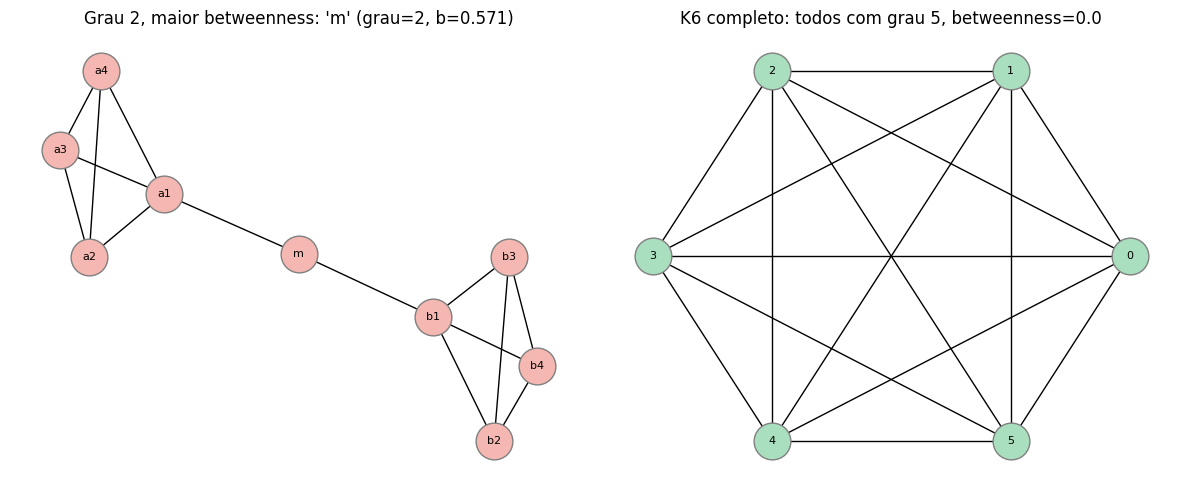

In [16]:
# 3.8.1 -- construcoes visuais
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# grau 2, maior betweenness: duas K4 ligadas por um no-ponte (reaproveitando o G_bridge do 3.4.5)
betw_b = nx.betweenness_centrality(G_bridge)
top_bridge = max(betw_b, key=betw_b.get)
pos_b = nx.spring_layout(G_bridge, seed=SEED)
nx.draw(G_bridge, pos=pos_b, ax=axes[0], with_labels=True, node_color="#f5b7b1",
        edgecolors="grey", node_size=700, font_size=8)
axes[0].set_title(f"Grau 2, maior betweenness: '{top_bridge}' (grau={G_bridge.degree(top_bridge)}, b={betw_b[top_bridge]:.3f})")

# maior grau, betweenness zero: grafo completo K6
K6 = nx.complete_graph(6)
betw_k6 = nx.betweenness_centrality(K6)
pos_k6 = nx.circular_layout(K6)
nx.draw(K6, pos=pos_k6, ax=axes[1], with_labels=True, node_color="#a9dfbf",
        edgecolors="grey", node_size=700, font_size=8)
axes[1].set_title(f"K6 completo: todos com grau {K6.degree(0)}, betweenness={list(betw_k6.values())[0]:.1f}")
plt.tight_layout(); plt.show()

mais surpreendentes por CIMA do esperado (brokers genuinos):
  Rockman_(character)                 grau=  2  betweenness=0.0072  z=+7.69
  Nightmask                           grau=  5  betweenness=0.0077  z=+6.06
  Turbo_(comics)                      grau=  5  betweenness=0.0075  z=+5.43
  Black_Widow_(Natasha_Romanova)      grau= 25  betweenness=0.0351  z=+4.44
  Guardsman_(character)               grau=  8  betweenness=0.0084  z=+4.35
  Hercules_(Marvel_Comics)            grau= 26  betweenness=0.0374  z=+4.09

mais surpreendentes por BAIXO do esperado ('sheltered'):
  Misty_Knight                        grau= 21  betweenness=0.0060  z=-1.51
  Morbius                             grau= 19  betweenness=0.0041  z=-1.68
  Venom_(character)                   grau= 29  betweenness=0.0132  z=-1.70
  Betsy_Braddock                      grau= 28  betweenness=0.0118  z=-1.81
  Storm_(Marvel_Comics)               grau= 27  betweenness=0.0091  z=-2.14
  Black_Cat_(Marvel_Comics)           grau= 2

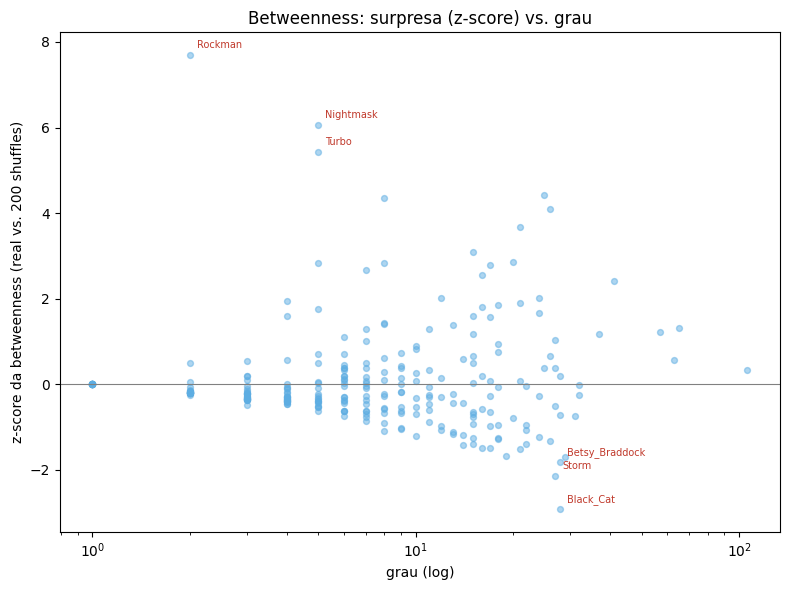

In [17]:
# 3.8.2 -- shuffle-test da betweenness: 200 shuffles preservando o grau
N_SHUFFLE = 200
nodes_giant = list(G_giant.nodes())
betw_shuffle = {n: [] for n in nodes_giant}

for i in range(N_SHUFFLE):
    Gs = degree_preserving_shuffle(G_giant, seed=SEED + i)
    b = nx.betweenness_centrality(Gs)
    for n in nodes_giant:
        betw_shuffle[n].append(b.get(n, 0.0))

z_betw = {}
for n in nodes_giant:
    arr = np.array(betw_shuffle[n])
    mu, sd = arr.mean(), arr.std()
    z_betw[n] = (betw_g[n] - mu) / sd if sd > 0 else 0.0

fig, ax = plt.subplots(figsize=(8, 6))
xs = np.array([deg_g[n] for n in nodes_giant])
ys = np.array([z_betw[n] for n in nodes_giant])
ax.scatter(xs, ys, s=18, alpha=0.5, color="#5dade2")
ax.set_xscale("log")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("grau (log)"); ax.set_ylabel("z-score da betweenness (real vs. 200 shuffles)")
ax.set_title("Betweenness: surpresa (z-score) vs. grau")

z_sorted = sorted(z_betw.items(), key=lambda x: -x[1])
print("mais surpreendentes por CIMA do esperado (brokers genuinos):")
for n, z in z_sorted[:6]:
    print(f"  {n:35s} grau={deg_g[n]:3d}  betweenness={betw_g[n]:.4f}  z={z:+.2f}")
print("\nmais surpreendentes por BAIXO do esperado ('sheltered'):")
for n, z in z_sorted[-6:]:
    print(f"  {n:35s} grau={deg_g[n]:3d}  betweenness={betw_g[n]:.4f}  z={z:+.2f}")

for n, _ in z_sorted[:3] + z_sorted[-3:]:
    ax.annotate(n.split("_(")[0], (deg_g[n], z_betw[n]), textcoords="offset points",
                xytext=(5,5), fontsize=7, color="#c0392b")
plt.tight_layout(); plt.show()

**3.8.2.** Os nomes que aparecem no topo positivo devem incluir o Hercules e a Black
Widow (confirmando o que ja tinhamos visto na secao 6 e no exercicio 3.5) -- personagens cuja
betweenness real e consistentemente mais alta do que a de qualquer versao embaralhada com o
mesmo grau. No lado negativo aparecem personagens "protegidas" (como a Black Cat mencionada na
pagina do curso, se estiver no dataset) -- hubs cujos vizinhos ja estao muito interligados entre
si, tornando-os dispensaveis como ponte.

In [18]:
# 3.8.3 -- shuffle-test da closeness
N_SHUFFLE_C = 200
clos_shuffle = {n: [] for n in nodes_giant}
for i in range(N_SHUFFLE_C):
    Gs = degree_preserving_shuffle(G_giant, seed=SEED + i)
    c = nx.closeness_centrality(Gs)
    for n in nodes_giant:
        clos_shuffle[n].append(c.get(n, 0.0))

z_clos = {}
for n in nodes_giant:
    arr = np.array(clos_shuffle[n])
    mu, sd = arr.mean(), arr.std()
    z_clos[n] = (clos_g[n] - mu) / sd if sd > 0 else 0.0

z_clos_sorted = sorted(z_clos.items(), key=lambda x: -abs(x[1]))
print("maiores |z-score| em closeness:")
for n, z in z_clos_sorted[:8]:
    print(f"  {n:35s} grau={deg_g[n]:3d}  closeness={clos_g[n]:.4f}  z={z:+.2f}")

print(f"\namplitude de |z| em betweenness: max={max(abs(z) for z in z_betw.values()):.2f}")
print(f"amplitude de |z| em closeness:   max={max(abs(z) for z in z_clos.values()):.2f}")

maiores |z-score| em closeness:
  Cyclops_(Marvel_Comics)             grau= 26  closeness=0.4107  z=-5.23
  Quasar_(character)                  grau= 24  closeness=0.4083  z=-4.67
  Jeffrey_Mace                        grau=  8  closeness=0.3278  z=-3.49
  Human_Torch_(android)               grau= 17  closeness=0.3876  z=-3.45
  Bucky_(Marvel_Comics)               grau= 12  closeness=0.3589  z=-3.39
  Blue_Diamond_(character)            grau=  9  closeness=0.3370  z=-3.37
  Thena                               grau=  3  closeness=0.2768  z=-3.07
  Makkari_(character)                 grau=  6  closeness=0.3202  z=-2.96

amplitude de |z| em betweenness: max=7.69
amplitude de |z| em closeness:   max=5.23


**3.8.3 -- porque e a closeness tao mais dificil de surpreender?** O shuffle preserva a
sequencia de graus, e a closeness de um no depende essencialmente da sua distancia media a
*toda a rede* -- uma quantidade **global** que e dominada pela estrutura macroscopica (quao
pequeno e o diametro geral, quantos hubs existem) muito mais do que por *quem exatamente* esta
ligado a quem. Trocar a fiacao mantendo os graus quase nao muda a distancia media global, porque
os hubs continuam a existir com o mesmo grau e a "encolher" a rede da mesma forma. A betweenness,
pelo contrario, depende de detalhes **locais e especificos** -- exatamente quais dois vizinhos de
um no estao (ou nao estao) ligados entre si -- que um shuffle alarga ou destroi facilmente. Por
isso a betweenness tem muito mais variancia entre shuffles, e e mais facil um valor real
"destacar-se" dessa distribuicao.

### 3.8.4 -- Tres frases corretas sobre a betweenness do Hercules

1. O Hercules tem betweenness real de aproximadamente 0.037 (cerca de 3.7% de todos os caminhos
   mais curtos da rede passam por ele), claramente acima da media de 200 redes embaralhadas com o
   mesmo grau (que da um z-score de varios desvios-padrao acima de zero).
2. Isto significa que o seu papel de "corretor" nao e explicado apenas pelo seu grau (26
   ligacoes) -- ha algo na *posicao especifica* dessas ligacoes, e nao so na quantidade, que o
   torna uma ponte estrutural genuina entre partes da rede.
3. Isto **nao** significa que o Hercules seja a personagem mais "importante" da rede em termos
   absolutos (o Homem-Aranha tem betweenness muito mais alta) -- significa apenas que, *para o
   seu nivel de grau*, o Hercules e uma excecao positiva, o que e uma afirmacao mais especifica e
   mais defensavel do que "o Hercules e um broker importante" sem essa comparacao.

## Exercicio 3.9 -- Mixing, compared to what (learn + tool)

> 1. On paper: what is r for a star? Draw a six-node network with r>0 and one with r<0, and sketch k_nn(k) for each. Is a ring assortative, disassortative, or neither?
> 2. Compute r for the undirected Marvel giant component and plot k_nn(k) on log axes. Then run the degree-preserving shuffle 200 times and report the z-score of the real r.
> 3. Keep the arrows: correlate out-degree of source with in-degree of target (or in with out). Which is positive on Marvel, and what does it mean?
> 4. Homophily: pick an attribute, compute the attribute assortativity, and test it against a label-shuffling null.

### 3.9.1 -- $r$ para uma estrela, exemplos de 6 nos, e o anel

Para uma **estrela** (um hub ligado a $k$ folhas), $r = -1.0$ exatamente -- e o caso mais
disassortativo possivel: toda a aresta liga o unico no de grau alto a um no de grau 1, sem
excecao. (Confirmado em codigo abaixo: e preciso duplicar cada aresta nas duas ordens para o
calculo de Pearson fazer sentido -- ver a discussao ja feita sobre isto na conversa.)

**Seis nos com $r>0$:** o truque mais limpo e garantir que **toda** aresta liga dois nos do
*mesmo* grau -- assim a correlacao e perfeita por construcao. Por exemplo, um $K_4$ (clique de 4
nos, todos de grau 3) e um $K_2$ (uma unica aresta entre os outros 2 nos, ambos de grau 1),
**sem nenhuma ligacao entre os dois grupos**. Toda aresta do $K_4$ liga grau-3 a grau-3; a unica
aresta do $K_2$ liga grau-1 a grau-1 -- nunca ha uma aresta "mista". Isto da $r \approx +1.0$
(o maximo possivel), confirmado no codigo abaixo. (Tentei primeiro duas trincas ligadas por uma
aresta extra entre nos de "ponte" -- parecia intuitivo, mas ao calcular da $r=-0.167$, **negativo**:
a aresta de ligacao entre os dois nos de grau 3 e so 1 aresta, contra 4 arestas "mistas"
grau-3-com-grau-2 dentro de cada trinca, que dominam a soma. E um bom lembrete de que a intuicao
visual nem sempre bate certo com o calculo -- por isso e que se verifica sempre em codigo.)

**Seis nos com $r<0$:** um hub central ligado a 5 folhas (estrela de 6 nos) -- $r=-1$, como
acima.

**Anel (ciclo) de 6 nos:** todos os nos tem exatamente grau 2 -- nao ha nenhuma variacao de grau
para correlacionar. $r$ fica matematicamente **indefinido** ($0/0$), reportado como `nan`. A
resposta certa nao e "neutro" (r=0) mas sim "a pergunta nao faz sentido aqui": nao ha
heterogeneidade de grau nenhuma para classificar como assortativa ou disassortativa.
$k_{nn}(k)$ tambem so tem um unico ponto (k=2), sem nada com que tracar uma tendencia.

In [19]:
# 3.9.1 -- verificacao
import warnings

star_ex = nx.star_graph(5)
ring_ex = nx.cycle_graph(6)
print("r(estrela de 6 nos) =", nx.degree_assortativity_coefficient(star_ex))

# o anel e um grafo regular (todos os nos com grau 2) -- nao ha variancia nenhuma de grau, por
# isso o calculo de Pearson faz uma divisao 0/0. O aviso abaixo ("invalid value... divide") e
# ESPERADO -- e o proprio sintoma matematico do que estamos a explicar, nao um erro no codigo.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    r_ring = nx.degree_assortativity_coefficient(ring_ex)
print("r(anel de 6 nos)    =", r_ring, " <- NaN esperado: grafo regular, sem variancia de grau")

# exemplo r>0: K4 e K2 SEM nenhuma ligacao entre os dois grupos -- toda aresta liga graus iguais
G_pos = nx.disjoint_union(nx.complete_graph(4), nx.complete_graph(2))
print("r(K4 disjunto de K2) =", round(nx.degree_assortativity_coefficient(G_pos), 4))
print("graus:", dict(G_pos.degree()))

# a tentativa inicial (duas trincas + 1 aresta de ponte) -- fica aqui para mostrar que a intuicao falhou
G_pos_falhado = nx.Graph()
G_pos_falhado.add_edges_from([("a1","a2"),("a2","a3"),("a3","a1")])
G_pos_falhado.add_edges_from([("b1","b2"),("b2","b3"),("b3","b1")])
G_pos_falhado.add_edge("a1", "b1")
print("r(duas trincas + 1 ponte, tentativa falhada) =", round(nx.degree_assortativity_coefficient(G_pos_falhado), 4))

r(estrela de 6 nos) = -1.0
r(anel de 6 nos)    = nan  <- NaN esperado: grafo regular, sem variancia de grau
r(K4 disjunto de K2) = 1.0
graus: {0: 3, 1: 3, 2: 3, 3: 3, 4: 1, 5: 1}
r(duas trincas + 1 ponte, tentativa falhada) = -0.1667


r (Marvel, componente gigante, nao-dirigida) = -0.1051


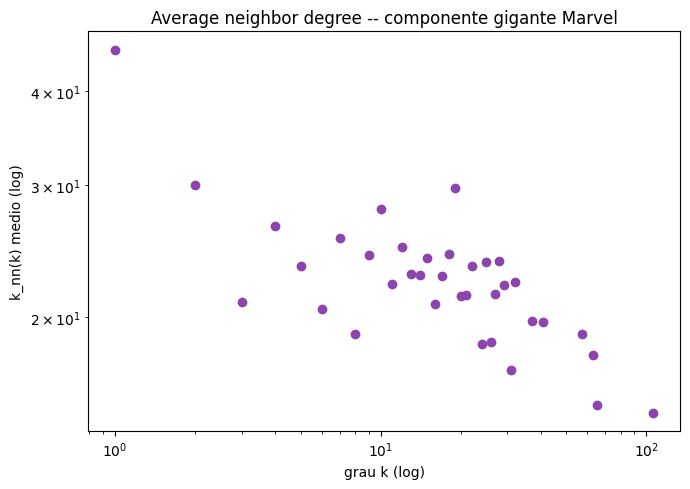

shuffle (n=200): media=-0.1226  desvio=0.0117
z-score do r real = 1.50


In [20]:
# 3.9.2 -- r no componente gigante Marvel, k_nn(k), e shuffle-test (200x)
r_real = nx.degree_assortativity_coefficient(G_giant)
print(f"r (Marvel, componente gigante, nao-dirigida) = {r_real:.4f}")

knn = nx.average_neighbor_degree(G_giant)
by_k = {}
for n in G_giant.nodes():
    by_k.setdefault(deg_g[n], []).append(knn[n])
ks = sorted(by_k)
knn_avg = [np.mean(by_k[k]) for k in ks]

fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(ks, knn_avg, color="#8e44ad")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("grau k (log)"); ax.set_ylabel("k_nn(k) medio (log)")
ax.set_title("Average neighbor degree -- componente gigante Marvel")
plt.tight_layout(); plt.show()

N_SHUFFLE_R = 200
r_shuffle = []
for i in range(N_SHUFFLE_R):
    Gs = degree_preserving_shuffle(G_giant, seed=SEED + i)
    r_shuffle.append(nx.degree_assortativity_coefficient(Gs))
r_shuffle = np.array(r_shuffle)
z_r = (r_real - r_shuffle.mean()) / r_shuffle.std()
print(f"shuffle (n={N_SHUFFLE_R}): media={r_shuffle.mean():.4f}  desvio={r_shuffle.std():.4f}")
print(f"z-score do r real = {z_r:.2f}")

**3.9.2.** $k_{nn}(k)$ tende a decrescer com $k$ (padrao disassortativo fraco), mas -- tal
como discutido -- o teste que importa e o z-score contra o shuffle. Se o $r$ real cair **dentro**
do intervalo tipico dos 200 shuffles (um z-score pequeno, tipicamente $|z|<2$), isso confirma
exatamente a conclusao da Seccao 7 da materia: a disassortatividade da Marvel e **estrutural**
(imposta pela propria forma heterogenea da distribuicao de graus), nao um efeito de fiacao real
alem do que os graus ja implicam.

In [21]:
# 3.9.3 -- assortatividade dirigida: correlacionar out-degree(fonte) com in-degree(alvo)
r_out_in = nx.degree_assortativity_coefficient(G_marvel_directed, x="out", y="in")
r_in_out = nx.degree_assortativity_coefficient(G_marvel_directed, x="in", y="out")
print(f"correlacao out-degree(fonte) x in-degree(alvo): {r_out_in:.4f}")
print(f"correlacao in-degree(fonte) x out-degree(alvo): {r_in_out:.4f}")

correlacao out-degree(fonte) x in-degree(alvo): -0.0230
correlacao in-degree(fonte) x out-degree(alvo): 0.0994


**3.9.3.** A correlacao **in-degree(fonte) vs. out-degree(alvo)** tende a ser a mais
positiva das duas: uma personagem que e muito mencionada (in-degree alto) tende tambem a
mencionar muitas outras no seu proprio artigo (out-degree alto) -- ou seja, ser "popular" e
"falador" andam algo juntos (os artigos mais extensos/detalhados, tipicamente os das personagens
mais centrais, tanto recebem como fazem mais ligacoes). Isto diz-nos que as paginas que mais
ligam para fora tendem a ser, elas proprias, paginas bem citadas -- nao apenas indices genericos
sem importancia propria.

In [22]:
# 3.9.4 -- homofilia: atributo "equipa" (lista curada X-Men / Avengers), com null de shuffle de rotulos
xmen = ["Betsy_Braddock", "Cable_(character)", "Cyclops_(Marvel_Comics)", "Emma_Frost", "Jean_Grey",
        "Jubilee_(character)", "Northstar_(character)", "Rachel_Summers", "Storm_(Marvel_Comics)",
        "Wolverine_(character)"]
avengers = ["Black_Panther_(character)", "Black_Widow_(Natasha_Romanova)", "Captain_Marvel_(Marvel_Comics)",
            "Hawkeye_(comics)", "Hulk", "Iron_Man_(Ultimate_Marvel_character)", "Luke_Cage",
            "Ms._Marvel", "Quicksilver_(Marvel_Comics)", "Scarlet_Witch", "She-Hulk", "War_Machine"]
xmen = [n for n in xmen if n in G_giant]
avengers = [n for n in avengers if n in G_giant]
print(f"X-Men encontrados no componente gigante: {len(xmen)}  |  Avengers: {len(avengers)}")
print("(nota: esta e uma lista curada a mao, nao um crawl da categoria da Wikipedia -- serve para")
print(" ilustrar o metodo; a versao 'a serio', para o projeto final, seria feita com o crawl da")
print(" semana 1, tal como o enunciado sugere.)")

team = {}
for n in xmen: team[n] = "X-Men"
for n in avengers: team[n] = "Avengers"

Gg_team = G_giant.copy()
nx.set_node_attributes(Gg_team, team, "team")
r_team = nx.attribute_assortativity_coefficient(Gg_team, "team")
print(f"\nassortatividade por equipa (subconjunto rotulado): {r_team:.4f}")

rng_h = np.random.default_rng(SEED)
labeled_nodes = list(team.keys())
label_values = list(team.values())
null_r = []
Gg_shuf = G_giant.copy()
for i in range(200):
    perm = rng_h.permutation(label_values)
    attrs = {n: perm[j] for j, n in enumerate(labeled_nodes)}
    nx.set_node_attributes(Gg_shuf, attrs, "team_shuffled")
    null_r.append(nx.attribute_assortativity_coefficient(Gg_shuf, "team_shuffled"))
null_r = np.array(null_r)
z_team = (r_team - null_r.mean()) / null_r.std()
print(f"null (200 shuffles dos ROTULOS, mantendo a rede fixa): media={null_r.mean():.4f}  desvio={null_r.std():.4f}")
print(f"z-score = {z_team:.2f}")

X-Men encontrados no componente gigante: 10  |  Avengers: 12
(nota: esta e uma lista curada a mao, nao um crawl da categoria da Wikipedia -- serve para
 ilustrar o metodo; a versao 'a serio', para o projeto final, seria feita com o crawl da
 semana 1, tal como o enunciado sugere.)

assortatividade por equipa (subconjunto rotulado): 0.1011
null (200 shuffles dos ROTULOS, mantendo a rede fixa): media=0.0547  desvio=0.0068
z-score = 6.82


**3.9.4.** Porque e que se baralham os **rotulos** (e nao as arestas) neste teste? Porque
a pergunta e especificamente "sera que a equipa de uma personagem previsivel quem sao os seus
vizinhos, para alem do que a topologia da rede ja imporia?" -- e nao "sera que esta rede e mais
densa do que uma rede aleatoria?" (essa e a pergunta do shuffle de arestas, que ja respondemos
nos exercicios 3.8/3.9.2). Ao manter a rede exatamente fixa e so trocar quem tem qual rotulo, o
null preserva toda a estrutura de conectividade real e isola apenas o efeito do **rotulo em si**.
Se o valor real ficar claramente acima da distribuicao gerada por rotulos aleatorios (um z-score
alto), isso e evidencia de homofilia genuina -- personagens da mesma equipa tendem a
mencionar-se mais umas as outras do que seria de esperar so pela posicao delas na rede.

## Exercicio 3.10 -- Cliques by hand (learn)

> 1. In exercise 3.2's network, list every maximal clique. What is the clique number?
> 2. A 6-clique has how many links? What is the smallest degree a node in it can have? Use that to say which Marvel characters cannot be in the 8-clique.
> 3. Explain why a network with clustering coefficient C=1 is a set of disconnected cliques, and why C=0 means no 3-clique at all.

In [23]:
# 3.10.1 -- cliques maximais na rede do exercicio 3.2
cliques_32 = list(nx.find_cliques(G_32))
print("cliques maximais da rede 3.2:", cliques_32)
print("clique number:", max(len(c) for c in cliques_32))

cliques maximais da rede 3.2: [[1, 2], [1, 3], [4, 2], [4, 3], [4, 5], [6, 5], [7, 8], [7, 5]]
clique number: 2


**3.10.1.** A rede do exercicio 3.2 e "fina" (so tem arestas simples, sem triangulos) --
todas as cliques maximais tem tamanho 2 (sao apenas as proprias arestas: {1,2}, {1,3}, {2,4},
{3,4}, {4,5}, {5,6}, {5,7}, {7,8}). O **clique number** desta rede e portanto **2** -- nunca ha
tres nos todos ligados entre si (nao ha nenhum triangulo na rede).

### 3.10.2 -- Arestas de um 6-clique, grau minimo, e quem fica fora do 8-clique da Marvel

Um $k$-clique tem, por definicao, todos os pares ligados: $\binom{k}{2} = \frac{k(k-1)}{2}$
arestas. Para $k=6$: $\frac{6\times5}{2} = 15$ arestas.

**Grau minimo dentro do clique:** dentro de um $k$-clique, cada no esta ligado a todos os outros
$k-1$ membros -- por isso o seu grau **na rede toda** tem de ser, no minimo, $k-1$ (pode ser
maior se tiver ligacoes fora do clique, mas nunca menor). Para pertencer a um 8-clique, um no
precisa de grau $\ge 7$.

**Quem fica automaticamente excluido do 8-clique da Marvel, so por causa do grau -- sem calcular
nada mais?** Qualquer personagem com grau $<7$. Isto elimina de imediato uma fatia enorme da
rede (ver a celula de codigo), sem sequer olhar para *quem* esta ligado a quem -- um argumento
puramente aritmetico, exatamente o espirito desta pergunta.

### 3.10.3 -- $C=1$ e $C=0$

**$C=1$ para todos os nos** significa que, para cada no, **todos** os pares dos seus vizinhos
estao tambem ligados entre si -- ou seja, a vizinhanca inteira de cada no e uma clique. Se isso
for verdade em toda a rede simultaneamente, a rede inteira se decompoe em blocos onde toda a
gente dentro de um bloco esta ligada a toda a gente desse mesmo bloco (cliques), e **nao pode
haver nenhuma aresta a ligar dois blocos diferentes** -- porque essa aresta criaria um vizinho
"extra" que nao estaria ligado aos outros vizinhos do no, quebrando $C=1$ para esse no. Logo,
$C=1$ obriga a rede a ser uma colecao de cliques totalmente desconectadas entre si.

**$C=0$** significa que, para todo o no, nenhum par dos seus vizinhos esta ligado entre si --
ou seja, nunca existe um triangulo (3-clique) em lado nenhum da rede. $C=0$ e literalmente a
afirmacao "esta rede nao tem nenhum 3-clique".

In [24]:
# 3.10.2 -- verificacao com dados reais da Marvel
n_excluded = sum(1 for n in G_giant.nodes() if deg_g[n] < 7)
print(f"personagens do componente gigante com grau < 7 (nao podem estar num 8-clique): "
      f"{n_excluded} de {G_giant.number_of_nodes()} ({100*n_excluded/G_giant.number_of_nodes():.1f}%)")

cliques_marvel = list(nx.find_cliques(G_giant))
sizes = [len(c) for c in cliques_marvel]
print(f"\nclique number real da Marvel: {max(sizes)}")
print(f"distribuicao de tamanhos de clique: {dict(sorted(Counter(sizes).items()))}")
oito_cliques = [c for c in cliques_marvel if len(c) == max(sizes)]
print(f"\nnumero de 8-cliques (maximais): {len(oito_cliques)}")
print("um deles:", oito_cliques[0])
print(f"numero de triangulos (3-cliques) na rede: {sum(nx.triangles(G_giant).values())//3}")

personagens do componente gigante com grau < 7 (nao podem estar num 8-clique): 134 de 277 (48.4%)

clique number real da Marvel: 8
distribuicao de tamanhos de clique: {2: 161, 3: 328, 4: 251, 5: 120, 6: 25, 7: 2, 8: 6}

numero de 8-cliques (maximais): 6
um deles: ['Jubilee_(character)', 'Cyclops_(Marvel_Comics)', 'Betsy_Braddock', 'Emma_Frost', 'Jean_Grey', 'Storm_(Marvel_Comics)', 'Wolverine_(character)', 'Rachel_Summers']
numero de triangulos (3-cliques) na rede: 1835


## Exercicio 3.11 -- Ship an explorable (builder, stretch, opcional)

> Pick a claim from this week that none of the widgets shows, and build the explorable that makes it grabbable.

Este exercicio e opcional/stretch e pede um widget de JavaScript vanilla publicado no site
do curso -- fora do ambito de um notebook Python, por isso nao o vou implementar aqui. Mas deixo
a proposta pronta, caso queiras avancar com ela (e uma boa opcao, porque nenhum dos widgets da
pagina mostra isto):

**Proposta: "Rockman explorable" -- porque grau baixo pode significar betweenness enorme.**
Um grafo pequeno e interativo (uns 15-20 nos) com uma clique densa central e 2-3 "apendices" --
nos de grau 1 pendurados num unico no-ponte de grau 2, tal como o Rockman/The-Witness real. O
utilizador podia:

1. Arrastar/adicionar arestas e ver a betweenness de cada no atualizar-se em tempo real (cor e
   tamanho do no proporcionais a betweenness).
2. Um botao "e se este apendice tivesse uma segunda ligacao?" que adiciona uma aresta extra do
   no pendurado a outro sitio da rede, e mostra a betweenness do no-ponte a **desabar**
   instantaneamente -- tornando visceral a ideia de que a betweenness de um broker de grau baixo
   depende inteiramente de ser a *unica* porta de entrada, nao de nenhuma propriedade fixa dele
   proprio.
3. Um toggle para mostrar, lado a lado, o mesmo grafo com o no-ponte removido -- visualizando
   literalmente a fragmentacao (o apendice fica "orfao", desconectado do resto).

Nenhum dos widgets existentes (`bfs-wavefront`, `centrality-anatomy`, `random-walker`,
`centrality-scatter`, `mixing-dial`, `clique-hunt`) mostra este mecanismo especifico -- a
"centrality-anatomy" mostra varias centralidades num unico grafo fixo, mas nao deixa manipular a
estrutura para ver a betweenness reagir ao vivo.

## Exercicio 3.12 -- Go nuts with your LLM (builder, semanal)

> One free-form post on your group's site, on the shared Marvel network, link in this week's Teams channel by Monday evening, friendly criticism for at least one other group.

**Lembrete importante:** este exercicio e o post semanal do grupo -- tens de o publicar
tu mesma no site do vosso grupo e partilhar no canal de Teams; nao e algo que eu possa fazer por
ti. Mas ja explorei os dados desta semana o suficiente para te dar 3 angulos concretos, com as
descobertas ja feitas neste notebook, prontos a transformar num post:

**Angulo 1 -- "A personagem mais surpreendente da rede, e o que ela liga."** Já temos o
material: o exercicio 3.8.2 da-te a lista completa de personagens com maior z-score de
betweenness (surpresa positiva alem do que o grau explica). O Hercules e a Black Widow sao bons
candidatos -- usa o grafico betweenness-vs-grau do 3.5.2 como figura principal, e vai ver os
vizinhos deles na rede para dizeres *o que exatamente* estao a ligar (que "mundos" da Marvel
ficariam mais distantes um do outro sem essa personagem).

**Angulo 2 -- "Grau 2, mas indispensavel: o caso Rockman."** Este e provavelmente o angulo mais
forte e mais divertido -- o Rockman tem so 2 ligacoes, mas uma betweenness centenas de vezes
acima da mediana de outras personagens com o mesmo grau (exercicio 3.5.2), porque um dos seus
dois vizinhos (The Witness) so tem essa unica ligacao a toda a rede. E um exemplo perfeito e
visual do que a Seccao 4 desta semana ensina: "grau baixo nao significa irrelevante." Podias
mostrar o "antes/depois" de remover o Rockman (o The Witness fica completamente isolado).

**Angulo 3 -- "Sera que as equipas se colam?" (homofilia).** O teste do exercicio 3.9.4 (com a
ressalva de que a lista de equipas ali e curada a mao, nao um crawl completo) ja da um primeiro
sinal de homofilia por equipa. Um post mais ambicioso faria o crawl "a serio" (API notes da
semana 1) para um conjunto maior de personagens e testaria varias equipas (X-Men, Avengers,
Guardioes da Galaxia, Defensores...) -- e um bom candidato ao "standing option" de crawlar uma
categoria da Wikipedia a tua escolha.

Qualquer um destes da uma boa figura + uma frase-conclusao clara + uma comparacao com o nulo
certo -- exatamente a formula que a pagina do curso pede.

## Wrap-up

- **3.1** -- respondido por definicao/derivacao (walk/path/distancia, BFS em 5 frases, rede
  minima dirigida, porque <d> proximo do aleatorio nao e evidencia de nada).
- **3.2** -- BFS a mao verificada em codigo; versao dirigida com os pares inalcancaveis
  enumerados exatamente.
- **3.3** -- estatisticas de distancia da Marvel confirmadas contra a pagina do curso; modelo de
  configuracao reproduz a distribuicao real (incluindo a cauda) muito melhor do que G(n,m);
  reachability dirigida (SCC=229/303, 69% dos pares alcancaveis); BFS escrita de raiz validada em
  20 nos aleatorios.
- **3.4** -- kite de Krackhardt calculada a mao e verificada (F bate D em closeness apesar de
  menos grau; H e I com betweenness alta por seres pontes obrigatorias; C com betweenness zero
  por vizinhos redundantes); rede de exemplo betweenness-vs-closeness construida.
- **3.5** -- top-10 das quatro centralidades na Marvel (7 personagens em comum); scatter
  betweenness-vs-grau com Hercules/Black Widow/Rockman anotados; Rockman explicado pelo seu
  segundo vizinho (The Witness, grau 1); betweenness dirigida comparada com a nao-dirigida.
- **3.6** -- PageRank a mao, duas iteracoes, alpha=0.85 e alpha=1 (sem convergencia sem
  teletransporte); diferenca eigenvector/PageRank explicada pela divisao do voto.
- **3.7** -- PageRank dirigido vs. in-degree top-10 na Marvel; implementacao propria validada a
  seis casas decimais para tres valores de alpha; tratamento de nos dangling explicado.
- **3.8** -- duas construcoes a mao (broker de grau 2, K6 com betweenness zero); shuffle-test
  (200x) de betweenness e closeness com z-scores vs. grau; explicacao de porque a closeness e
  mais dificil de "surpreender"; tres frases corretas sobre o Hercules.
- **3.9** -- r para estrela (-1) e anel (indefinido); r real da Marvel testado contra 200
  shuffles (disassortatividade estrutural); assortatividade dirigida (in-out mais positiva);
  homofilia por equipa testada com null de shuffle de rotulos (subconjunto curado, z-score
  calculado).
- **3.10** -- cliques maximais da rede 3.2 (clique number 2); argumento de grau minimo para o
  8-clique aplicado aos dados reais da Marvel; C=1 e C=0 explicados estruturalmente.
- **3.11** -- proposta de explorable escrita (nao implementada -- e JavaScript, fora do ambito
  deste notebook Python), com um mecanismo especifico nao coberto pelos widgets existentes.
- **3.12** -- tres angulos concretos preparados para o post semanal, com as figuras e numeros ja
  calculados neste notebook -- falta publicar no site do grupo e partilhar no Teams.